# 📊 BNPL Credit Risk Dataset — Full Analysis
> **Alur:** Data Understanding → Data Cleaning → Feature Engineering → EDA → Hypothesis Testing → Customer Segmentation → Export
>
> **Dataset:** Buy Now Pay Later (BNPL) Credit Risk | 10.345 baris × 17 kolom

## 0. Setup & Import Library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, pointbiserialr
from sklearn.preprocessing import StandardScaler
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'figure.figsize': (10, 5)
})

---
## 1. Data Understanding
Memahami struktur, tipe data, missing values, duplikasi, dan distribusi awal dataset.

### 1.1 Load Data & Dimensi

In [ ]:
df = pd.read_csv('../data/Buy_Now_Pay_Later_BNPL_CreditRisk_Dataset.csv')
df.shape

(10345, 17)

### 1.2 Tipe Data

In [ ]:
df.dtypes

,0
user_id,int64
age,int64
employment_type,object
monthly_income,float64
credit_score,int64
purchase_amount,float64
product_category,object
bnpl_installments,int64
repayment_delay_days,int64
missed_payments,int64


### 1.3 Info Umum

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10345 entries, 0 to 10344
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   user_id               10345 non-null  int64  
 1   age                   10345 non-null  int64  
 2   employment_type       10345 non-null  object 
 3   monthly_income        10345 non-null  float64
 4   credit_score          10345 non-null  int64  
 5   purchase_amount       10345 non-null  float64
 6   product_category      10345 non-null  object 
 7   bnpl_installments     10345 non-null  int64  
 8   repayment_delay_days  10345 non-null  int64  
 9   missed_payments       10345 non-null  int64  
 10  default_flag          10345 non-null  int64  
 11  app_usage_frequency   10345 non-null  float64
 12  location              10345 non-null  object 
 13  transaction_date      10345 non-null  object 
 14  debt_to_income_ratio  10345 non-null  float64
 15  risk_score         

### 1.4 Preview Data

In [ ]:
df.head()

,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment
0,1,56,Salaried,68529.50,552,5000.00,Electronics,12,13,1,0,8.49,Australia,2023-06-10,0.072961,165.2,Medium Risk
1,2,19,Student,7247.85,300,1073.23,Fashion,12,13,1,0,3.09,USA,2024-10-07,0.148076,266.0,High Risk
2,3,20,Self-Employed,41582.26,471,5000.00,Electronics,3,19,2,0,3.33,Australia,2023-04-05,0.120244,229.6,High Risk
3,4,21,Salaried,14423.46,300,4076.83,Sports,6,18,5,1,5.86,Germany,2023-06-24,0.282653,356.0,High Risk
4,5,43,Salaried,42845.50,512,5000.00,Electronics,9,0,0,0,7.36,India,2024-10-19,0.116698,135.2,High Risk


In [ ]:
df.tail()

,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment
10340,10341,52,Student,17344.34,393,5000.00,Fashion,6,0,0,1,4.33,USA,2024-10-25,0.288278,182.8,High Risk
10341,10342,53,Student,17788.20,300,100.00,Sports,12,12,1,0,1.41,Australia,2023-06-15,0.005622,264.0,High Risk
10342,10343,42,Self-Employed,59350.25,535,5000.00,Home,12,4,2,0,5.07,Australia,2024-09-24,0.084246,174.0,High Risk
10343,10344,59,Self-Employed,73739.74,678,5000.00,Beauty,3,2,0,0,8.89,Germany,2023-01-19,0.067806,72.8,Medium Risk
10344,10345,23,Unemployed,6345.21,360,1015.57,Sports,9,0,0,1,3.10,India,2024-07-09,0.160053,196.0,High Risk


In [ ]:
df.sample(5, random_state=42)

,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment
1190,1191,20,Unemployed,8546.40,319,3276.37,Fashion,3,9,2,0,1.41,USA,2023-05-08,0.383363,270.4,High Risk
9948,9949,34,Self-Employed,11686.10,300,2872.76,Fashion,9,14,2,0,8.94,Canada,2023-03-11,0.245827,288.0,High Risk
4001,4002,30,Salaried,12822.98,326,4465.20,Electronics,12,2,3,1,5.46,India,2023-01-26,0.348219,273.6,High Risk
3287,3288,38,Student,54036.53,511,5000.00,Beauty,3,4,0,1,7.69,Germany,2023-03-20,0.092530,143.6,High Risk
2794,2795,28,Self-Employed,58883.42,529,5000.00,Fashion,9,0,0,1,9.11,Canada,2023-06-15,0.084914,128.4,High Risk


### 1.5 Statistik Deskriptif — Numerik

In [ ]:
df.describe()

,user_id,age,monthly_income,credit_score,purchase_amount,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,debt_to_income_ratio,risk_score
count,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000
mean,5173.000000,38.559884,35053.381898,448.176124,3979.402721,7.477525,8.742774,1.015950,0.390527,5.524101,0.181071,198.534094
std,2986.488601,12.131789,27084.517277,136.518332,1500.828483,3.362867,6.781849,0.996726,0.487892,2.590364,0.124887,67.541384
min,1.000000,18.000000,5000.000000,300.000000,100.000000,3.000000,0.000000,0.000000,0.000000,1.000000,0.000811,0.000000
25%,2587.000000,28.000000,12207.020000,332.000000,2990.720000,3.000000,2.000000,0.000000,0.000000,3.300000,0.080187,153.600000
50%,5173.000000,39.000000,23800.520000,403.000000,5000.000000,9.000000,9.000000,1.000000,0.000000,5.550000,0.138263,202.800000
75%,7759.000000,49.000000,55276.930000,547.000000,5000.000000,9.000000,14.000000,2.000000,1.000000,7.750000,0.268300,250.800000
max,10345.000000,59.000000,145767.120000,850.000000,5000.000000,12.000000,33.000000,7.000000,1.000000,10.000000,0.723460,398.000000


### 1.6 Statistik Deskriptif — Kategorikal

In [ ]:
df.describe(include='object')

,employment_type,product_category,location,transaction_date,customer_segment
count,10345,10345,10345,10345,10345
unique,4,5,6,365,3
top,Salaried,Fashion,Germany,2024-08-15,High Risk
freq,2632,2166,1760,42,7569


### 1.7 Missing Values

In [ ]:
df.isnull().sum()

,0
user_id,0
age,0
employment_type,0
monthly_income,0
credit_score,0
purchase_amount,0
product_category,0
bnpl_installments,0
repayment_delay_days,0
missed_payments,0


In [ ]:
df.isnull().mean().mul(100).round(2)

,0
user_id,0.0
age,0.0
employment_type,0.0
monthly_income,0.0
credit_score,0.0
purchase_amount,0.0
product_category,0.0
bnpl_installments,0.0
repayment_delay_days,0.0
missed_payments,0.0


### 1.8 Duplikasi

In [ ]:
df.duplicated().sum()

np.int64(0)

### 1.9 Kardinalitas Kolom Kategorikal

In [ ]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    display(df[col].value_counts().rename(col))

,employment_type
employment_type,
Salaried,2632
Unemployed,2632
Self-Employed,2550
Student,2531


,product_category
product_category,
Fashion,2166
Electronics,2085
Beauty,2072
Home,2052
Sports,1970


,location
location,
Germany,1760
Canada,1740
USA,1736
India,1723
Australia,1722
UK,1664


,transaction_date
transaction_date,
2024-08-15,42
2024-08-18,41
2024-07-30,40
2024-09-04,40
2023-04-17,39
...,...
2024-08-04,16
2023-03-06,16
2024-10-23,15


,customer_segment
customer_segment,
High Risk,7569
Medium Risk,2200
Low Risk,576


### 1.10 Distribusi Target — `default_flag`

In [ ]:
df['default_flag'].value_counts()

,count
default_flag,
0,6305
1,4040


In [ ]:
df['default_flag'].value_counts(normalize=True).mul(100).round(2)

,proportion
default_flag,
0,60.95
1,39.05


### 1.11 Distribusi `customer_segment`

In [ ]:
df['customer_segment'].value_counts()

,count
customer_segment,
High Risk,7569
Medium Risk,2200
Low Risk,576


---
## 2. Data Cleaning
Konversi tipe data, validasi range logis, penanganan outlier, dan normalisasi string.

In [ ]:
df_clean = df.copy()

### 2.1 Konversi Tipe Data

In [ ]:
df_clean['transaction_date'] = pd.to_datetime(df_clean['transaction_date'])

df_clean['default_flag'] = df_clean['default_flag'].astype('int8')

for col in ['employment_type', 'product_category', 'location', 'customer_segment']:
    df_clean[col] = df_clean[col].astype('category')

df_clean.dtypes

,0
user_id,int64
age,int64
employment_type,category
monthly_income,float64
credit_score,int64
purchase_amount,float64
product_category,category
bnpl_installments,int64
repayment_delay_days,int64
missed_payments,int64


### 2.2 Validasi Range Logis

In [ ]:
display(df_clean[df_clean['age'] < 18])
display(df_clean[df_clean['age'] > 59])

,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment


,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment


In [ ]:
df_clean['credit_score'].agg(['min', 'max'])

,credit_score
min,300
max,850


In [ ]:
df_clean[df_clean['monthly_income'] <= 0]

,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment


In [ ]:
display(df_clean[df_clean['repayment_delay_days'] < 0])
display(df_clean[df_clean['missed_payments'] < 0])

,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment


,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment


In [ ]:
df_clean[(df_clean['debt_to_income_ratio'] < 0) | (df_clean['debt_to_income_ratio'] > 1)]

,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment


### 2.3 Penanganan Outlier — IQR Capping

In [ ]:
outlier_cols = ['monthly_income', 'repayment_delay_days',
                'missed_payments', 'debt_to_income_ratio', 'risk_score']

for col in outlier_cols:
    Q1  = df_clean[col].quantile(0.25)
    Q3  = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lb  = Q1 - 1.5 * IQR
    ub  = Q3 + 1.5 * IQR
    df_clean[col] = df_clean[col].clip(lower=lb, upper=ub)

df_clean[outlier_cols].describe()

,monthly_income,repayment_delay_days,missed_payments,debt_to_income_ratio,risk_score
count,10345.000000,10345.000000,10345.000000,10345.000000,10345.000000
mean,35035.945169,8.742678,1.015080,0.180790,198.549502
std,27025.448544,6.781510,0.992706,0.123954,67.496347
min,5000.000000,0.000000,0.000000,0.000811,7.800000
25%,12207.020000,2.000000,0.000000,0.080187,153.600000
50%,23800.520000,9.000000,1.000000,0.138263,202.800000
75%,55276.930000,14.000000,2.000000,0.268300,250.800000
max,119881.795000,32.000000,5.000000,0.550470,396.600000


### 2.4 Strip Whitespace Kolom Kategorikal

In [ ]:
for col in df_clean.select_dtypes(include='category').columns:
    df_clean[col] = df_clean[col].cat.rename_categories(lambda x: x.strip())

df_clean.head(2)

,user_id,age,employment_type,monthly_income,credit_score,purchase_amount,product_category,bnpl_installments,repayment_delay_days,missed_payments,default_flag,app_usage_frequency,location,transaction_date,debt_to_income_ratio,risk_score,customer_segment
0,1,56,Salaried,68529.50,552,5000.00,Electronics,12,13,1,0,8.49,Australia,2023-06-10,0.072961,165.2,Medium Risk
1,2,19,Student,7247.85,300,1073.23,Fashion,12,13,1,0,3.09,USA,2024-10-07,0.148076,266.0,High Risk


---
## 3. Feature Engineering / Data Manipulation
Membuat fitur baru dari kolom yang ada untuk memperkaya analisis dan persiapan ML.

In [ ]:
df_feat = df_clean.copy()

### 3.1 Ekstrak Komponen Tanggal

In [ ]:
df_feat['txn_year']    = df_feat['transaction_date'].dt.year
df_feat['txn_month']   = df_feat['transaction_date'].dt.month
df_feat['txn_quarter'] = df_feat['transaction_date'].dt.quarter
df_feat['txn_dow']     = df_feat['transaction_date'].dt.day_name()

df_feat[['transaction_date','txn_year','txn_month','txn_quarter','txn_dow']].head(3)

,transaction_date,txn_year,txn_month,txn_quarter,txn_dow
0,2023-06-10,2023,6,2,Saturday
1,2024-10-07,2024,10,4,Monday
2,2023-04-05,2023,4,2,Wednesday


### 3.2 Fitur Turunan Finansial

In [ ]:
df_feat['monthly_installment'] = df_feat['purchase_amount'] / df_feat['bnpl_installments']

df_feat['installment_income_ratio'] = df_feat['monthly_installment'] / df_feat['monthly_income']

df_feat['total_debt_estimate'] = df_feat['debt_to_income_ratio'] * df_feat['monthly_income']

df_feat[['monthly_installment','installment_income_ratio','total_debt_estimate']].describe()

,monthly_installment,installment_income_ratio,total_debt_estimate
count,10345.000000,10345.000000,10345.000000
mean,692.648827,0.031584,3976.942338
std,488.856630,0.030573,1500.501019
min,8.333333,0.000070,97.273988
25%,407.766667,0.010705,2979.380000
50%,555.555556,0.022198,5000.000000
75%,833.333333,0.039875,5000.000000
max,1666.666667,0.241153,5000.000000


### 3.3 Fitur Perilaku Pembayaran

In [ ]:
df_feat['ever_delayed'] = (df_feat['repayment_delay_days'] > 0).astype('int8')

df_feat['delay_category'] = pd.cut(
    df_feat['repayment_delay_days'],
    bins=[-np.inf, 0, 7, 14, np.inf],
    labels=['No Delay', 'Mild (1-7d)', 'Moderate (8-14d)', 'Severe (>14d)']
)

df_feat['delay_category'].value_counts()

,count
delay_category,
Mild (1-7d),3557
Moderate (8-14d),3184
Severe (>14d),2385
No Delay,1219


### 3.4 Kategori Credit Score (Standar Industri)

In [ ]:
df_feat['credit_tier'] = pd.cut(
    df_feat['credit_score'],
    bins=[0, 350, 450, 550, 650, np.inf],
    labels=['Very Poor', 'Poor', 'Fair', 'Good', 'Excellent']
)

df_feat['credit_tier'].value_counts()

,count
credit_tier,
Very Poor,3345
Poor,2753
Fair,1717
Good,1471
Excellent,1059


### 3.5 Binning Usia

In [ ]:
df_feat['age_group'] = pd.cut(
    df_feat['age'],
    bins=[17, 25, 35, 45, 60],
    labels=['18-25', '26-35', '36-45', '46-59']
)

df_feat['age_group'].value_counts()

,count
age_group,
46-59,3479
26-35,2486
36-45,2433
18-25,1947


### 3.6 Flag Status Pekerjaan

In [ ]:
df_feat['is_employed'] = df_feat['employment_type'].isin(
    ['Salaried', 'Self-Employed']
).astype('int8')

df_feat['is_employed'].value_counts()

,count
is_employed,
1,5182
0,5163


### 3.7 Standardisasi Kolom Numerik (Z-Score)

In [ ]:
num_cols = ['monthly_income', 'credit_score', 'purchase_amount',
            'risk_score', 'debt_to_income_ratio', 'app_usage_frequency']

scaler_std = StandardScaler()
df_scaled  = df_feat[num_cols].copy()
df_scaled[[f'{c}_zscore' for c in num_cols]] = scaler_std.fit_transform(df_scaled[num_cols])

df_scaled.head(3)

,monthly_income,credit_score,purchase_amount,risk_score,debt_to_income_ratio,app_usage_frequency,monthly_income_zscore,credit_score_zscore,purchase_amount_zscore,risk_score_zscore,debt_to_income_ratio_zscore,app_usage_frequency_zscore
0,68529.50,552,5000.00,165.2,0.072961,8.49,1.239394,0.760549,0.680055,-0.494117,-0.869953,1.145029
1,7247.85,300,1073.23,266.0,0.148076,3.09,-1.028269,-1.085446,-1.936473,0.999369,-0.263938,-0.939721
2,41582.26,471,5000.00,229.6,0.120244,3.33,0.242240,0.167194,0.680055,0.460055,-0.488484,-0.847065


### 3.8 Agregasi Default Rate per Segmen

In [ ]:
df_feat.groupby('employment_type', observed=True)['default_flag'].agg(
    total='count', defaults='sum', default_rate='mean'
).round(3)

,total,defaults,default_rate
employment_type,,,
Salaried,2632,861,0.327
Self-Employed,2550,669,0.262
Student,2531,1229,0.486
Unemployed,2632,1281,0.487


In [ ]:
df_feat.groupby('location', observed=True)['default_flag'].agg(
    total='count', defaults='sum', default_rate='mean'
).round(3)

,total,defaults,default_rate
location,,,
Australia,1722,670,0.389
Canada,1740,675,0.388
Germany,1760,709,0.403
India,1723,656,0.381
UK,1664,658,0.395
USA,1736,672,0.387


In [ ]:
df_feat.groupby('customer_segment', observed=True).agg(
    avg_income=('monthly_income', 'mean'),
    avg_credit_score=('credit_score', 'mean'),
    avg_risk_score=('risk_score', 'mean'),
    avg_dti=('debt_to_income_ratio', 'mean'),
    default_rate=('default_flag', 'mean')
).round(3)

,avg_income,avg_credit_score,avg_risk_score,avg_dti,default_rate
customer_segment,,,,,
High Risk,23030.366,385.959,225.978,0.215,0.496
Low Risk,93948.972,759.354,63.944,0.052,0.061
Medium Risk,60916.094,580.759,139.427,0.097,0.115


---
## 4. Exploratory Data Analysis (EDA)
Visualisasi mendalam untuk memahami pola, distribusi, korelasi, dan faktor-faktor yang mempengaruhi default.

### 4.1 Distribusi Variabel Numerik

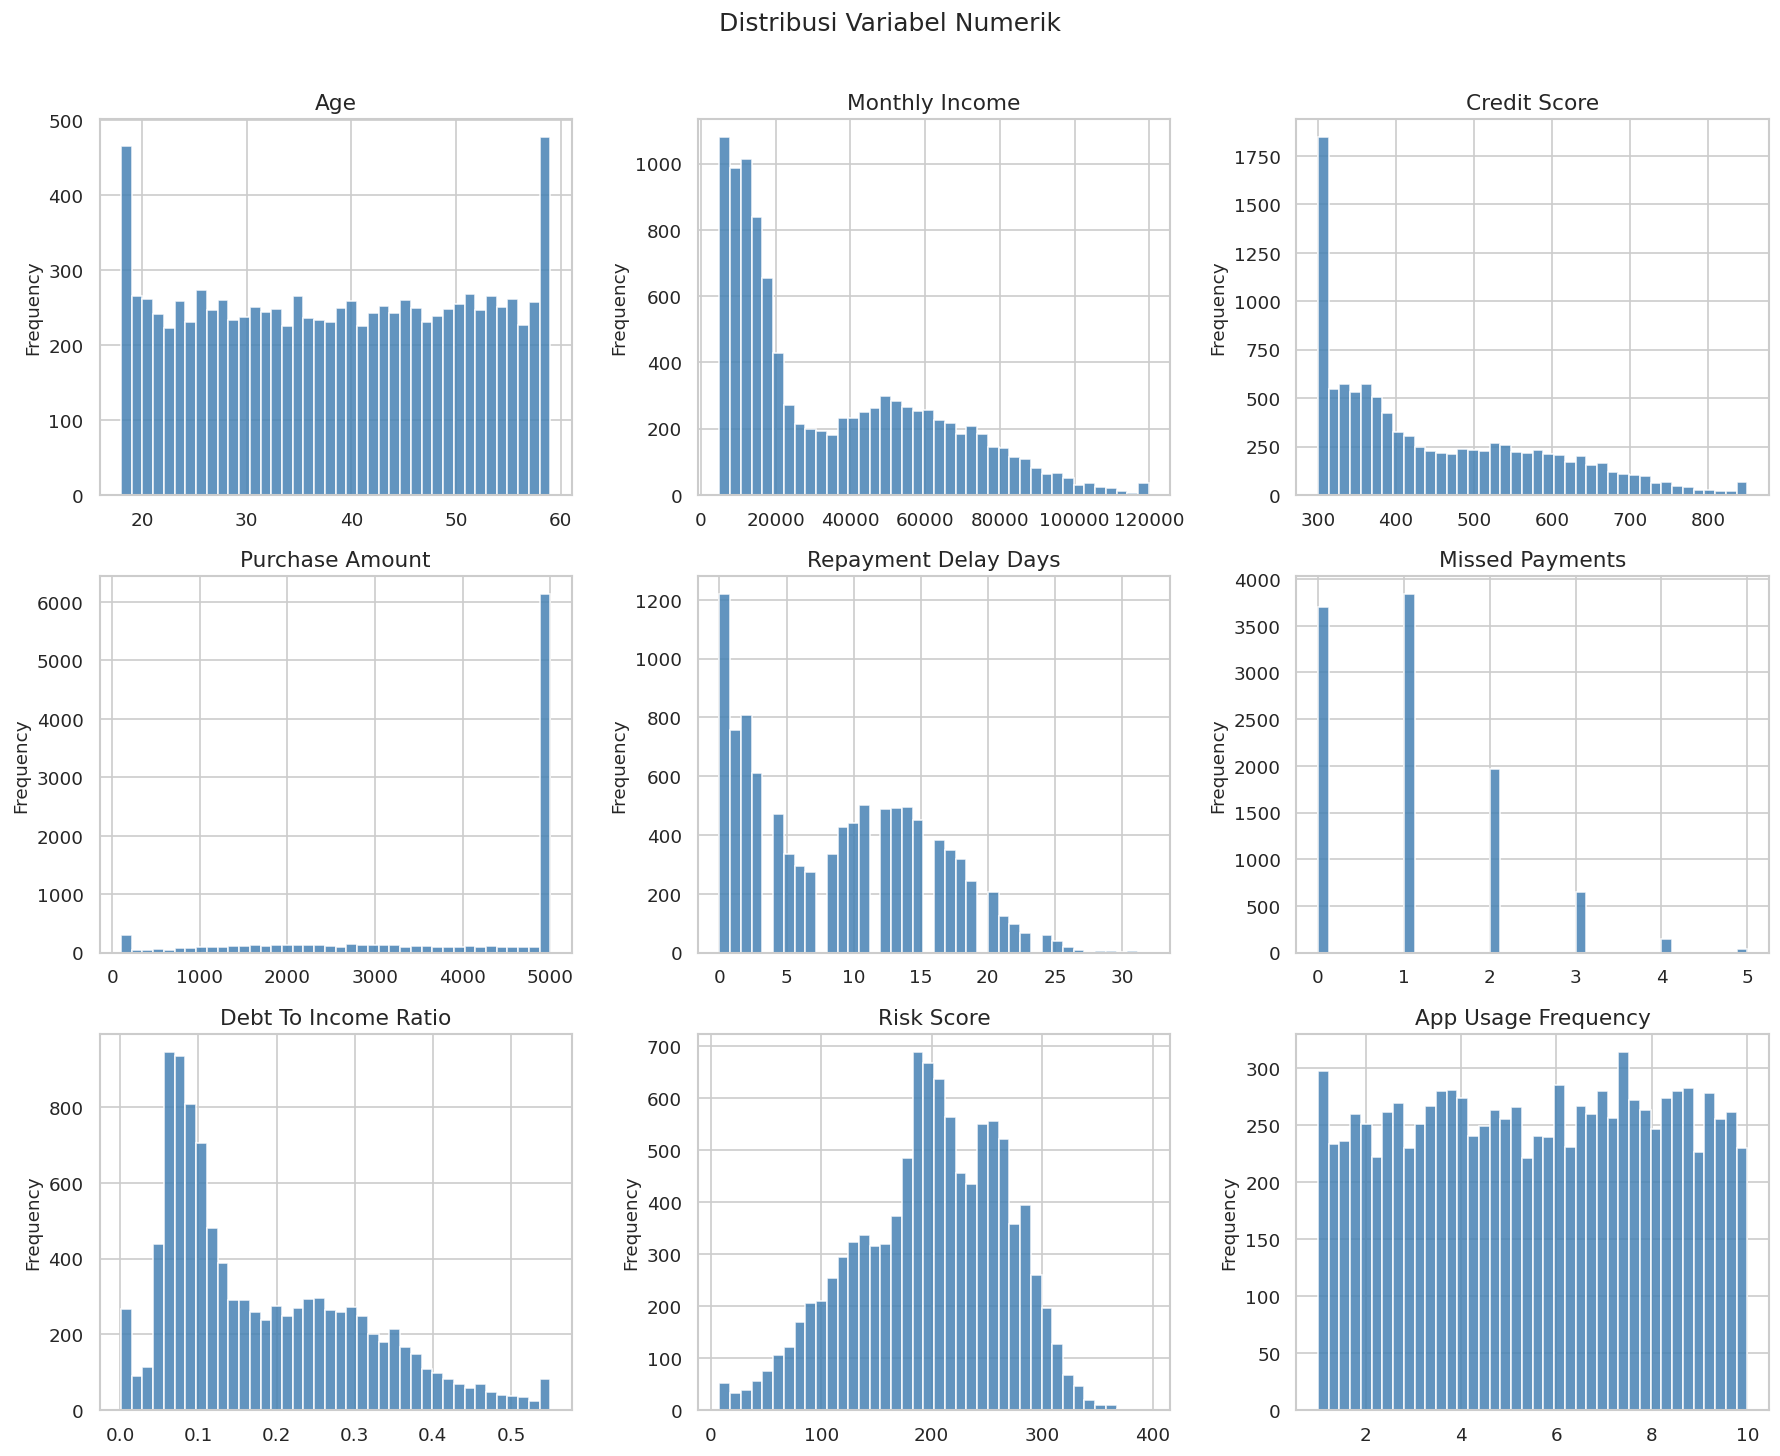

In [ ]:
num_eda = ['age', 'monthly_income', 'credit_score', 'purchase_amount',
           'repayment_delay_days', 'missed_payments', 'debt_to_income_ratio',
           'risk_score', 'app_usage_frequency']

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(num_eda):
    axes[i].hist(df_feat[col], bins=40, color='steelblue', edgecolor='white', alpha=0.85)
    axes[i].set_title(col.replace('_', ' ').title())
    axes[i].set_ylabel('Frequency')
plt.suptitle('Distribusi Variabel Numerik', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

### 4.2 Distribusi Variabel Kategorikal

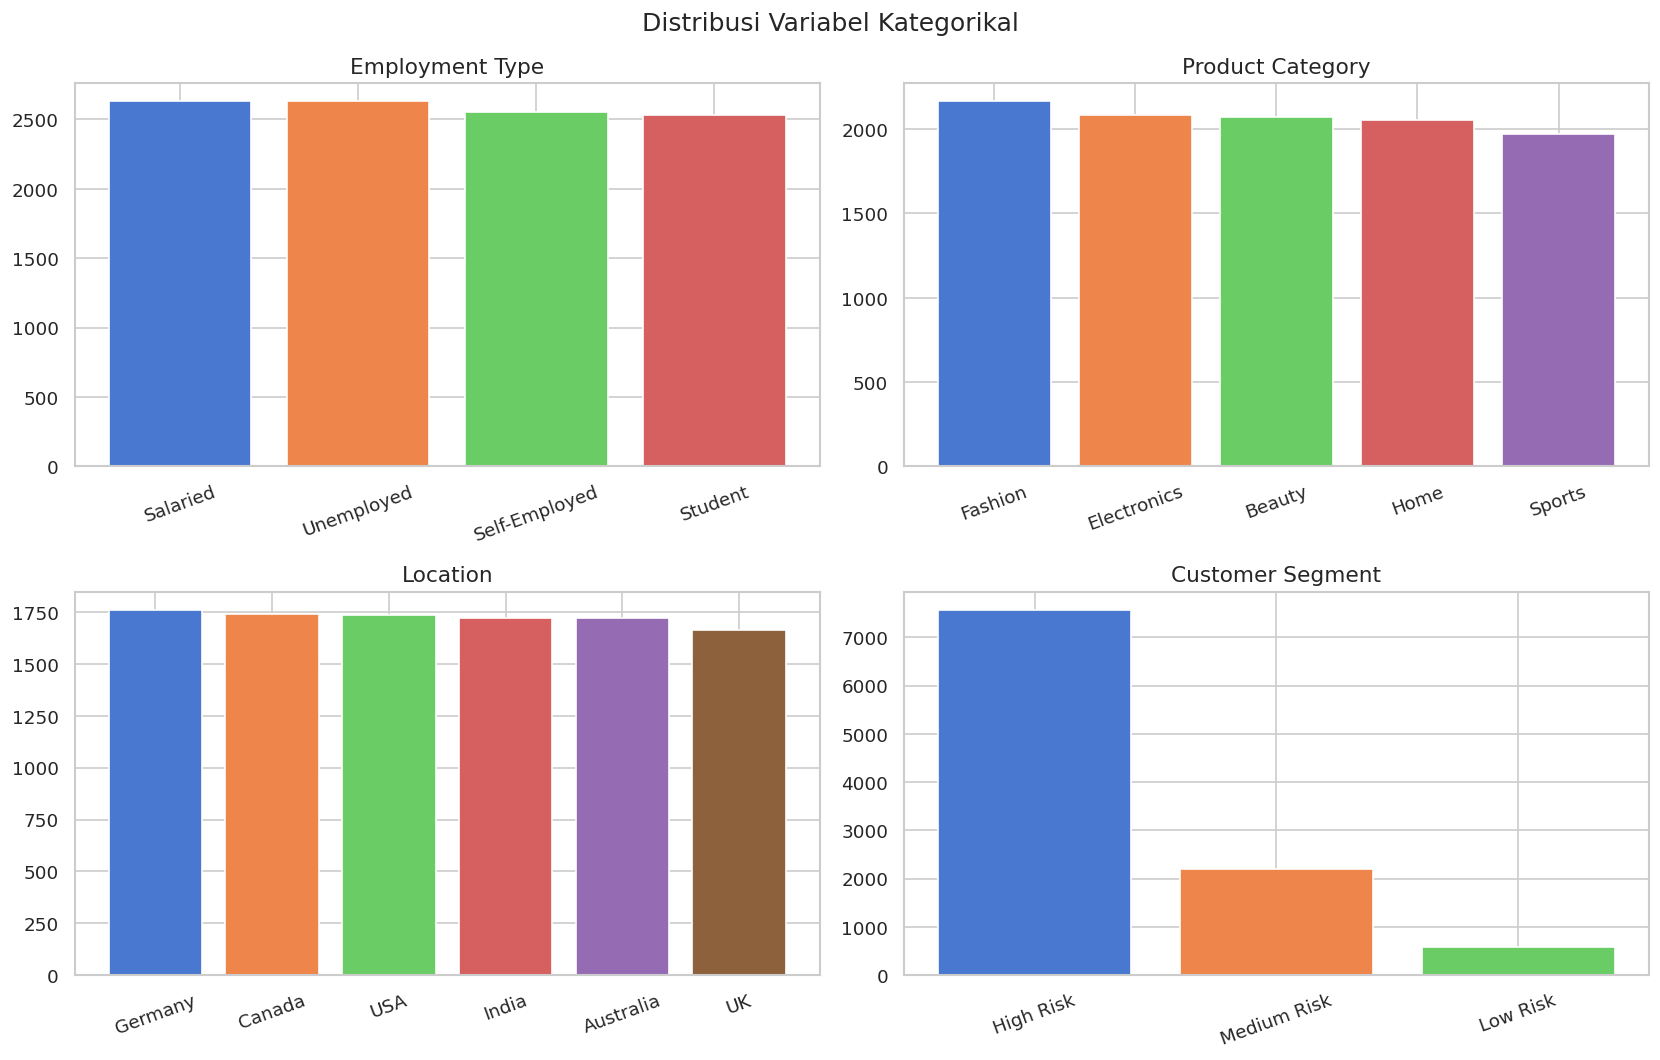

In [ ]:
cat_plot_cols = ['employment_type', 'product_category', 'location', 'customer_segment']

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()
for i, col in enumerate(cat_plot_cols):
    vc = df_feat[col].value_counts()
    axes[i].bar(vc.index, vc.values, color=sns.color_palette('muted', len(vc)))
    axes[i].set_title(col.replace('_', ' ').title())
    axes[i].tick_params(axis='x', rotation=20)
plt.suptitle('Distribusi Variabel Kategorikal', fontsize=15)
plt.tight_layout()
plt.show()

### 4.3 Default Rate per Variabel Kategorikal

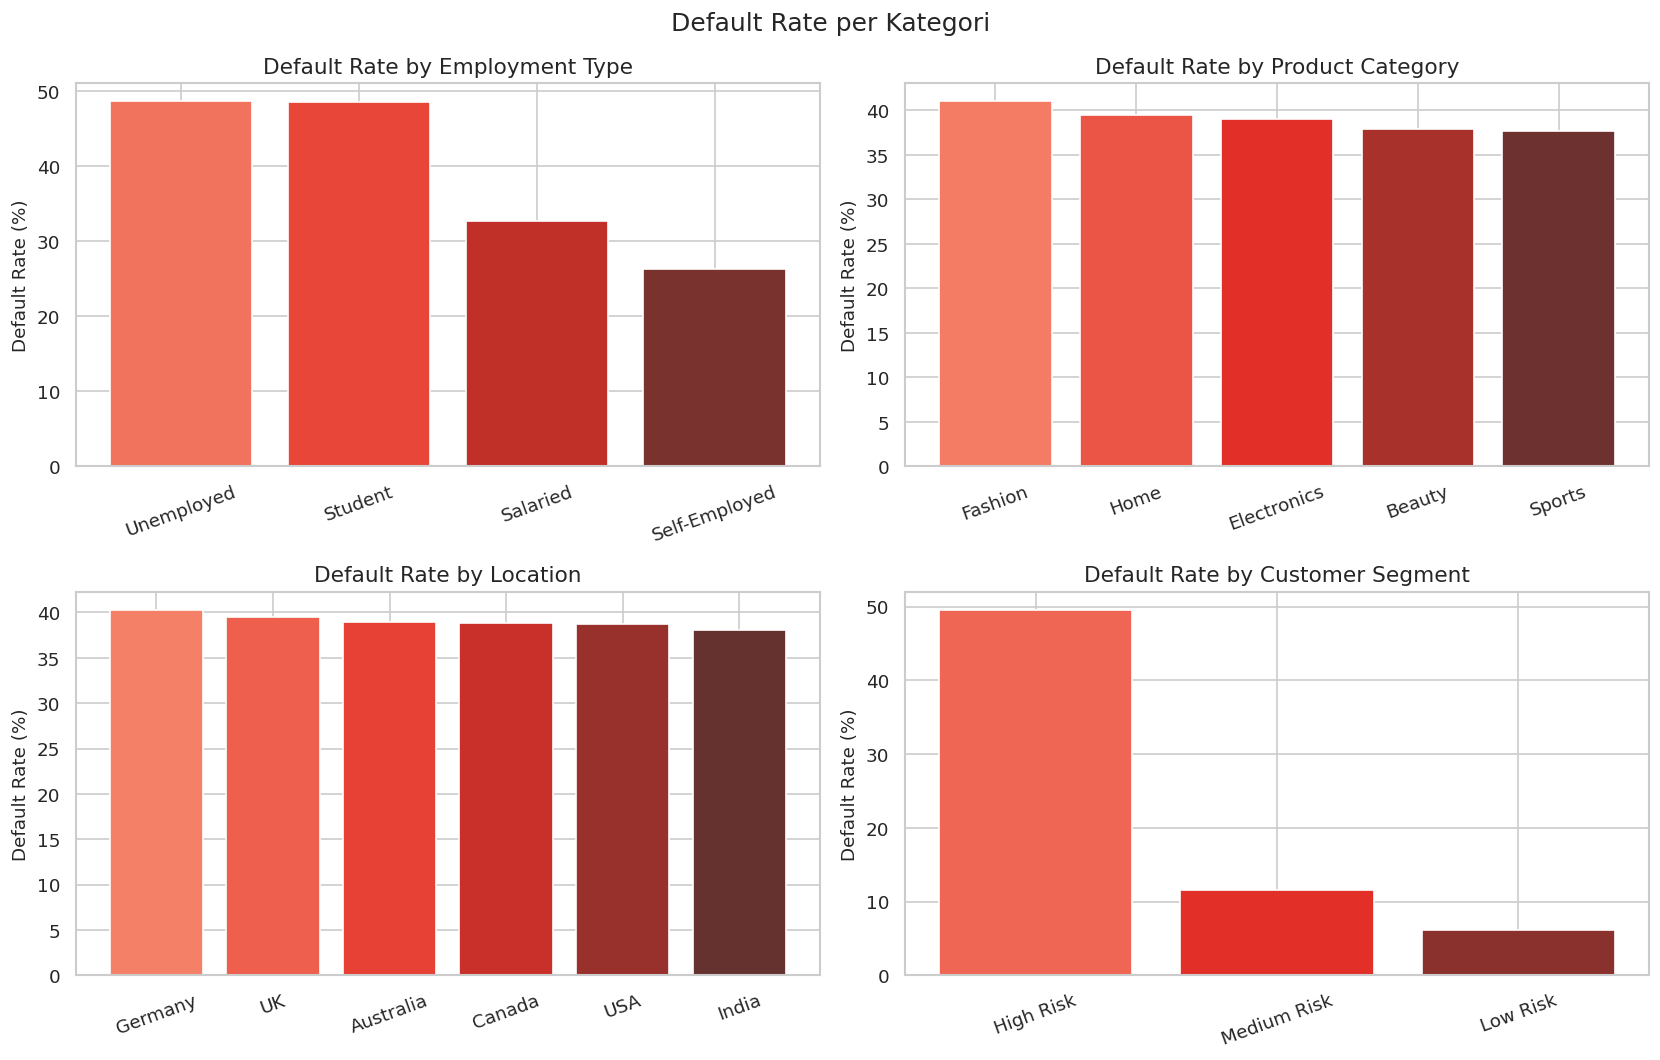

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()
for i, col in enumerate(cat_plot_cols):
    grp = df_feat.groupby(col, observed=True)['default_flag'].mean().sort_values(ascending=False)
    axes[i].bar(grp.index, grp.values * 100, color=sns.color_palette('Reds_d', len(grp)))
    axes[i].set_title(f'Default Rate by {col.replace("_"," ").title()}')
    axes[i].set_ylabel('Default Rate (%)')
    axes[i].tick_params(axis='x', rotation=20)
plt.suptitle('Default Rate per Kategori', fontsize=15)
plt.tight_layout()
plt.show()

### 4.4 Boxplot Fitur Numerik vs Default Flag

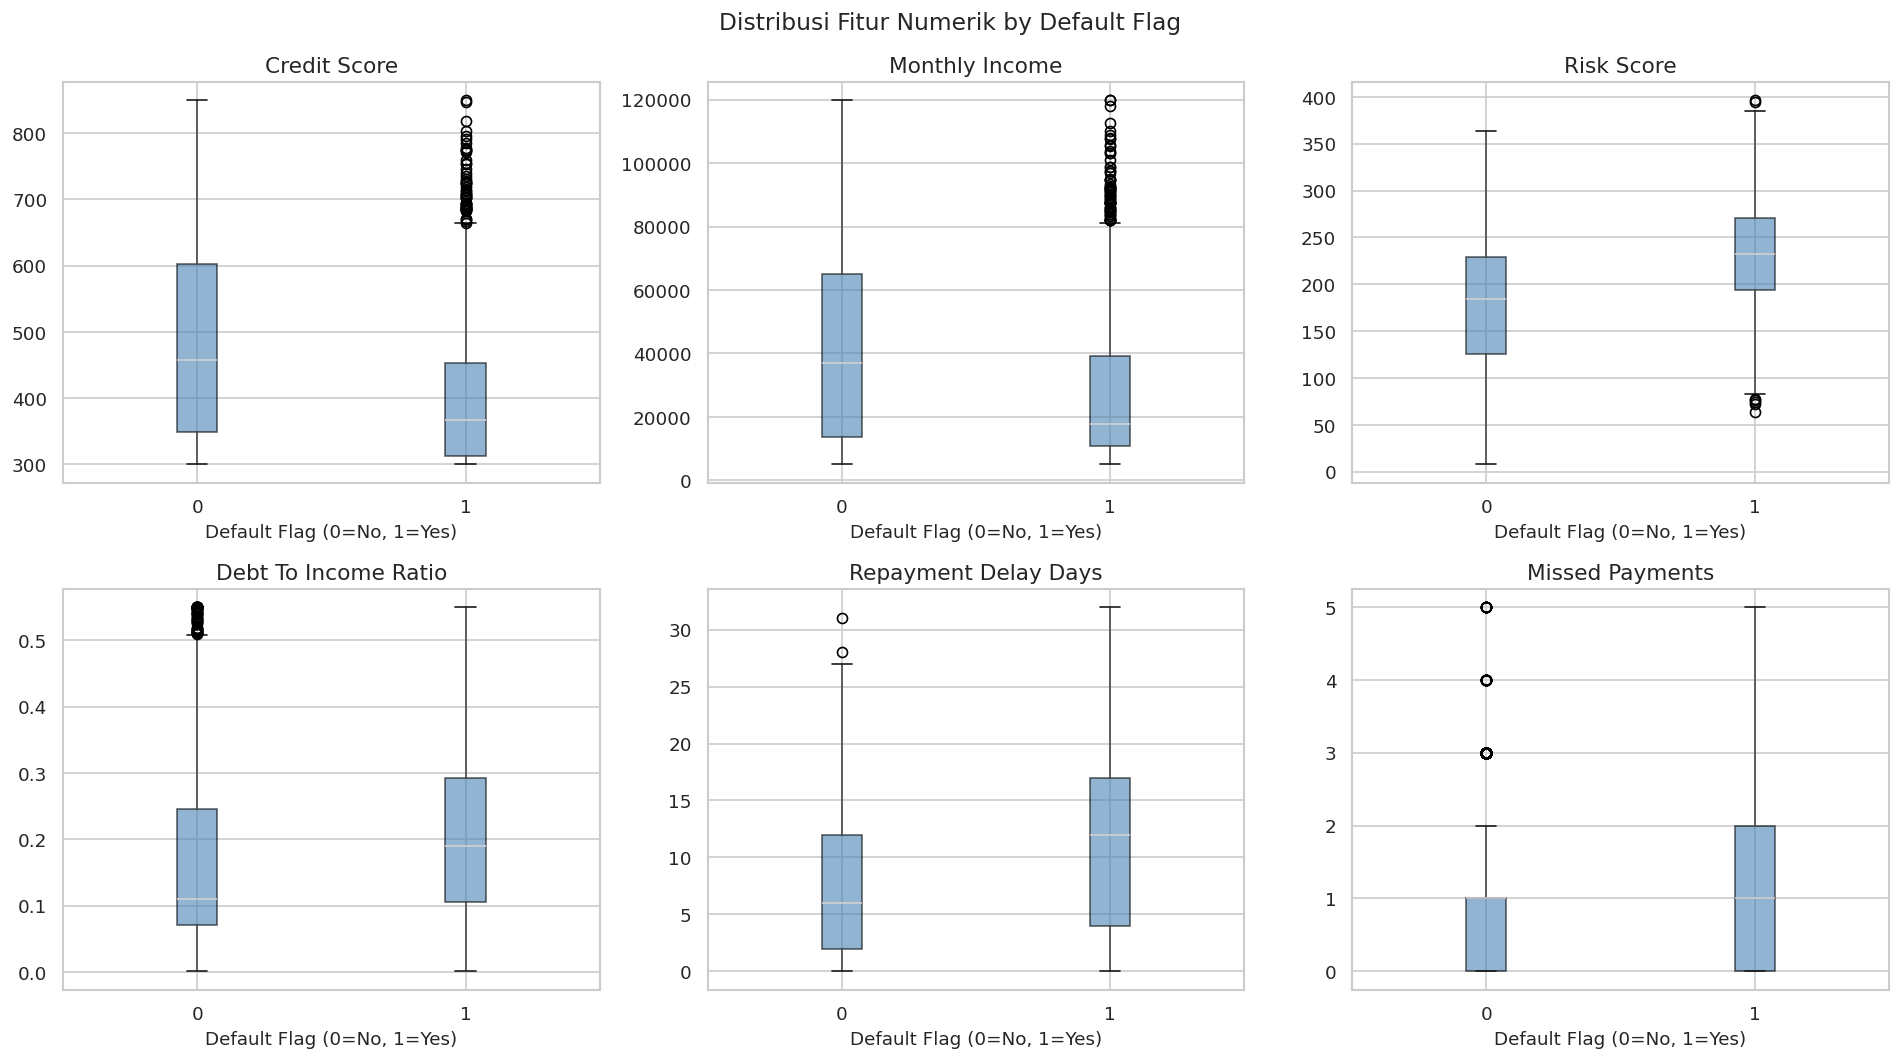

In [ ]:
box_cols = ['credit_score', 'monthly_income', 'risk_score',
            'debt_to_income_ratio', 'repayment_delay_days', 'missed_payments']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for i, col in enumerate(box_cols):
    df_feat.boxplot(column=col, by='default_flag', ax=axes[i],
                    patch_artist=True,
                    boxprops=dict(facecolor='steelblue', alpha=0.6))
    axes[i].set_xlabel('Default Flag (0=No, 1=Yes)')
    plt.sca(axes[i])
    plt.title(col.replace('_', ' ').title())
plt.suptitle('Distribusi Fitur Numerik by Default Flag', fontsize=14)
plt.tight_layout()
plt.show()

### 4.5 Correlation Heatmap

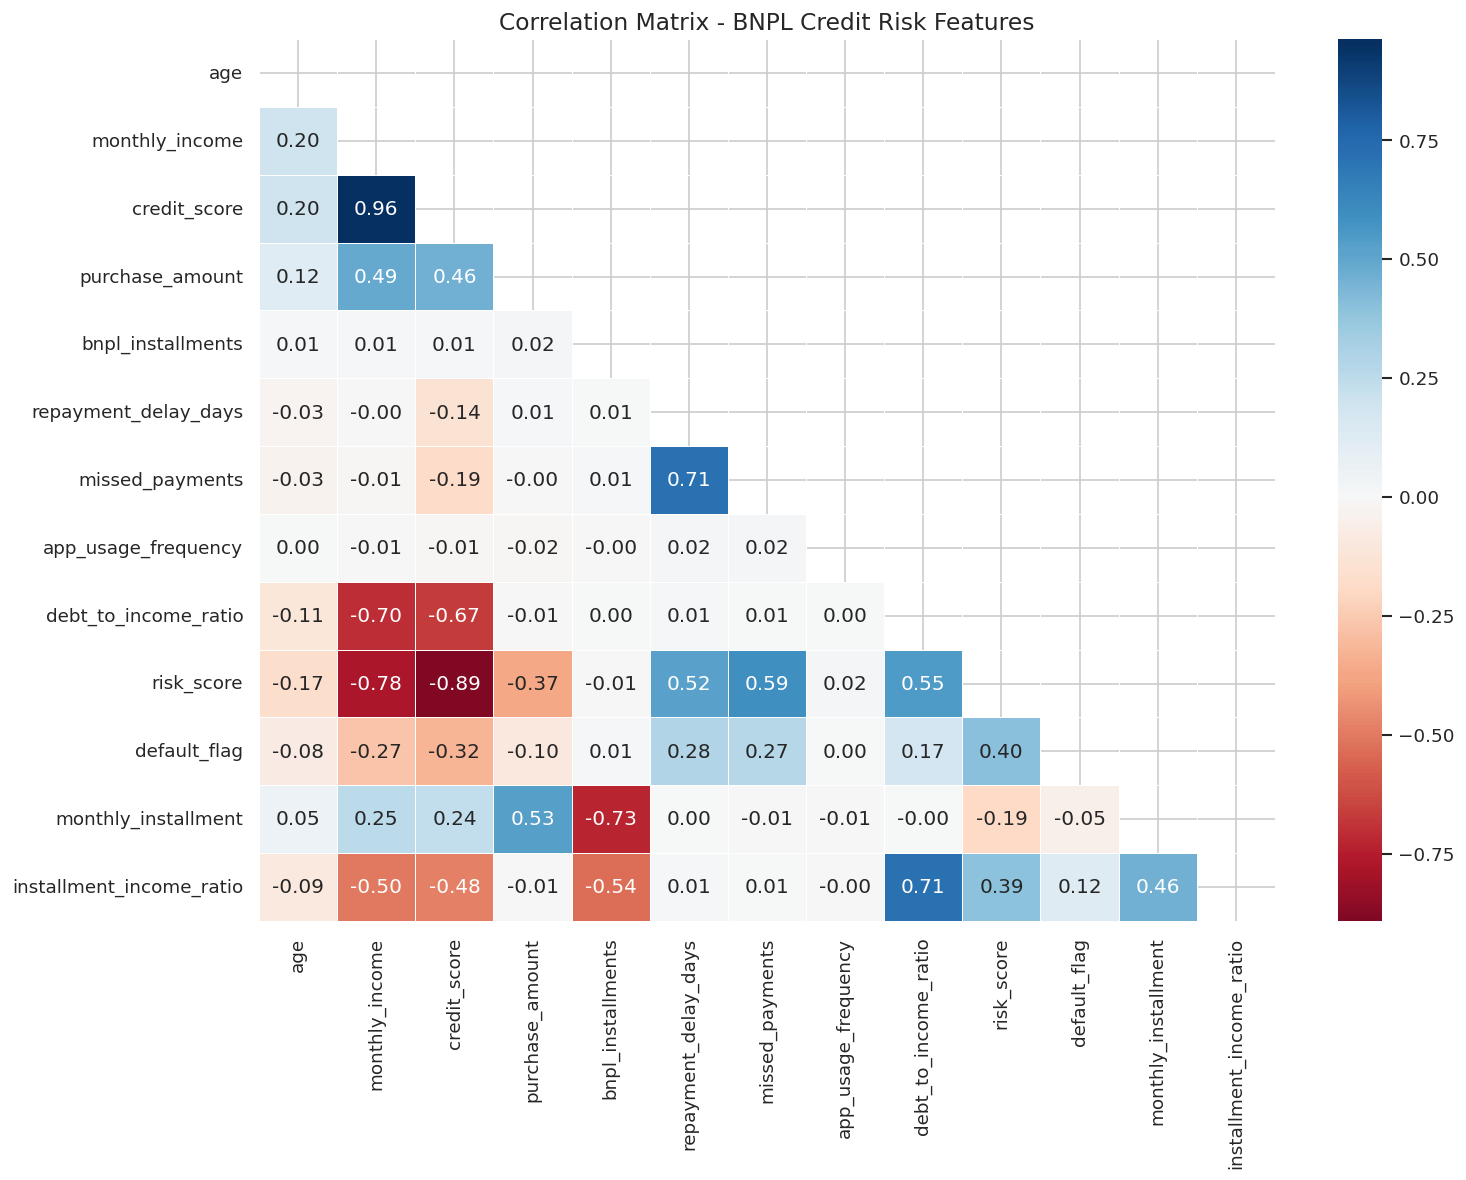

In [ ]:
corr_cols = ['age', 'monthly_income', 'credit_score', 'purchase_amount',
             'bnpl_installments', 'repayment_delay_days', 'missed_payments',
             'app_usage_frequency', 'debt_to_income_ratio', 'risk_score',
             'default_flag', 'monthly_installment', 'installment_income_ratio']

corr_matrix = df_feat[corr_cols].corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu',
            center=0, linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix - BNPL Credit Risk Features', fontsize=14)
plt.tight_layout()
plt.show()

### 4.6 Scatter — Credit Score vs Risk Score

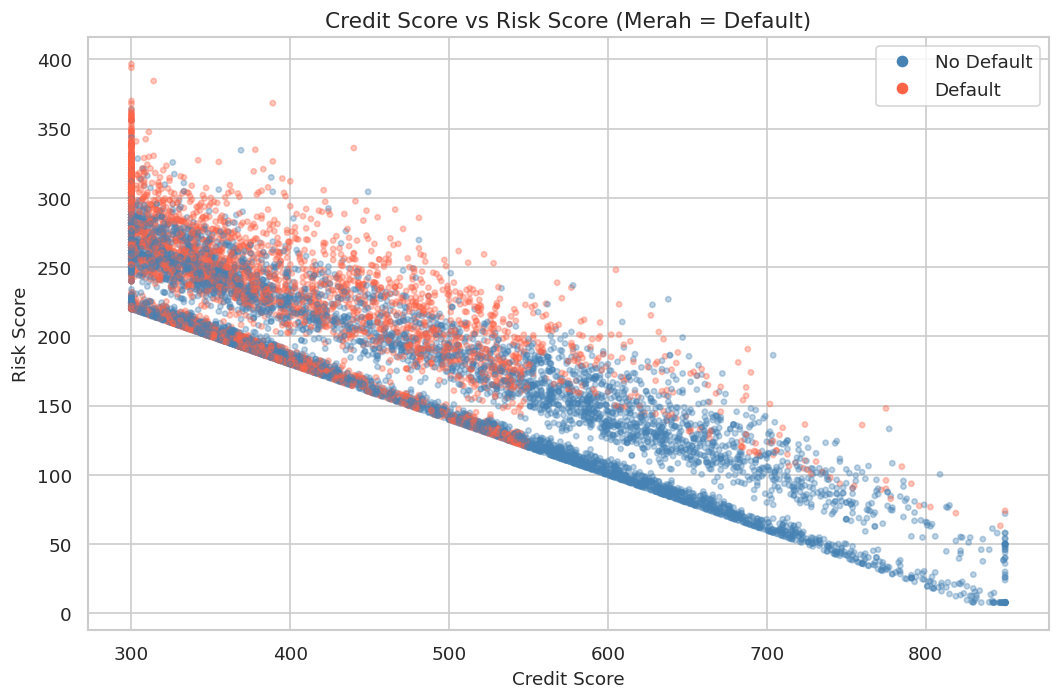

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
colors = df_feat['default_flag'].map({0: 'steelblue', 1: 'tomato'})
ax.scatter(df_feat['credit_score'], df_feat['risk_score'],
           c=colors, alpha=0.35, s=10)
ax.set_xlabel('Credit Score')
ax.set_ylabel('Risk Score')
ax.set_title('Credit Score vs Risk Score (Merah = Default)')
legend_els = [
    Line2D([0],[0], marker='o', color='w', markerfacecolor='steelblue', markersize=8, label='No Default'),
    Line2D([0],[0], marker='o', color='w', markerfacecolor='tomato',    markersize=8, label='Default')
]
ax.legend(handles=legend_els)
plt.tight_layout()
plt.show()

### 4.7 Default Rate by Age Group & Employment Type

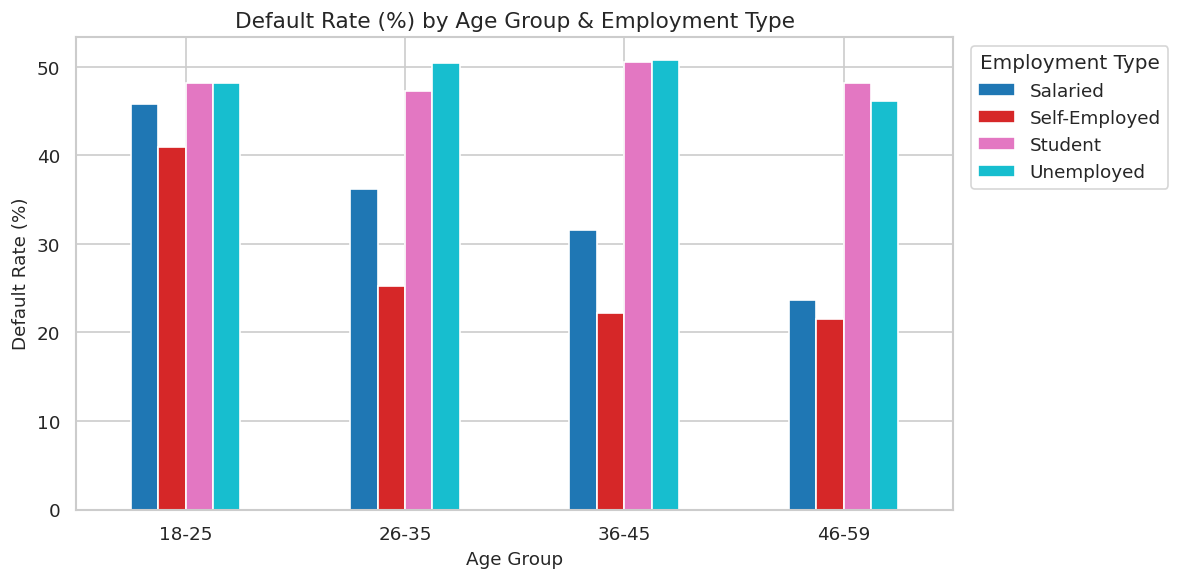

In [ ]:
pivot = df_feat.groupby(['age_group', 'employment_type'], observed=True)['default_flag'] \
               .mean().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
pivot.mul(100).plot(kind='bar', ax=ax, colormap='tab10', edgecolor='white')
ax.set_title('Default Rate (%) by Age Group & Employment Type')
ax.set_ylabel('Default Rate (%)')
ax.set_xlabel('Age Group')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Employment Type', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### 4.8 Trend Default Rate per Bulan

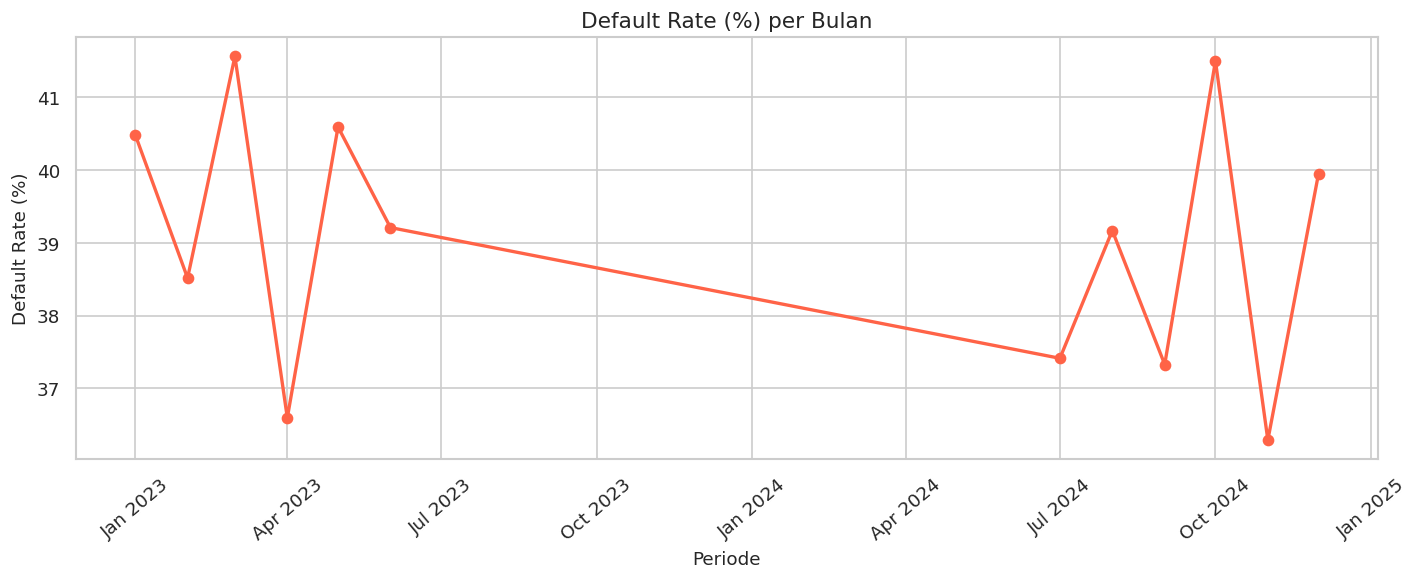

In [ ]:
monthly_trend = (
    df_feat.groupby(['txn_year', 'txn_month'])['default_flag']
    .agg(total='count', defaults='sum')
    .assign(default_rate=lambda x: x['defaults'] / x['total'] * 100)
    .reset_index()
)
monthly_trend['period'] = pd.to_datetime(
    monthly_trend['txn_year'].astype(str) + '-' + monthly_trend['txn_month'].astype(str)
)
monthly_trend.sort_values('period', inplace=True)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly_trend['period'], monthly_trend['default_rate'],
        marker='o', linewidth=2, color='tomato')
ax.set_title('Default Rate (%) per Bulan')
ax.set_ylabel('Default Rate (%)')
ax.set_xlabel('Periode')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.tick_params(axis='x', rotation=40)
plt.tight_layout()
plt.show()

### 4.9 KDE — Risk Score per Customer Segment

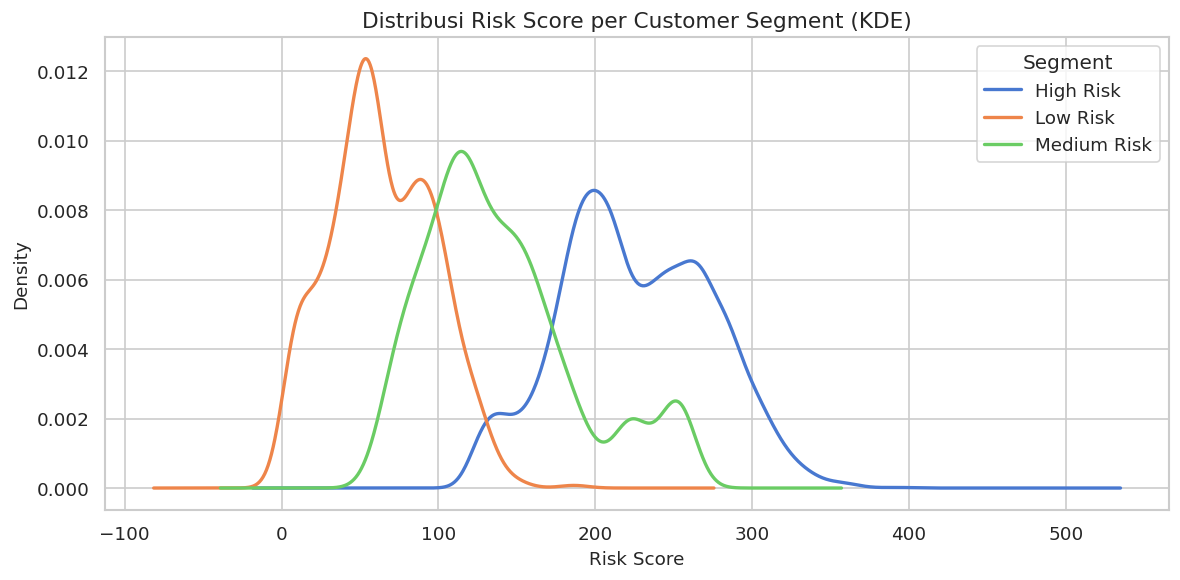

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
for seg in df_feat['customer_segment'].cat.categories:
    subset = df_feat[df_feat['customer_segment'] == seg]['risk_score']
    subset.plot.kde(ax=ax, label=seg, linewidth=2)
ax.set_title('Distribusi Risk Score per Customer Segment (KDE)')
ax.set_xlabel('Risk Score')
ax.legend(title='Segment')
plt.tight_layout()
plt.show()

### 4.10 Stacked Bar — Delay Category vs Default Status

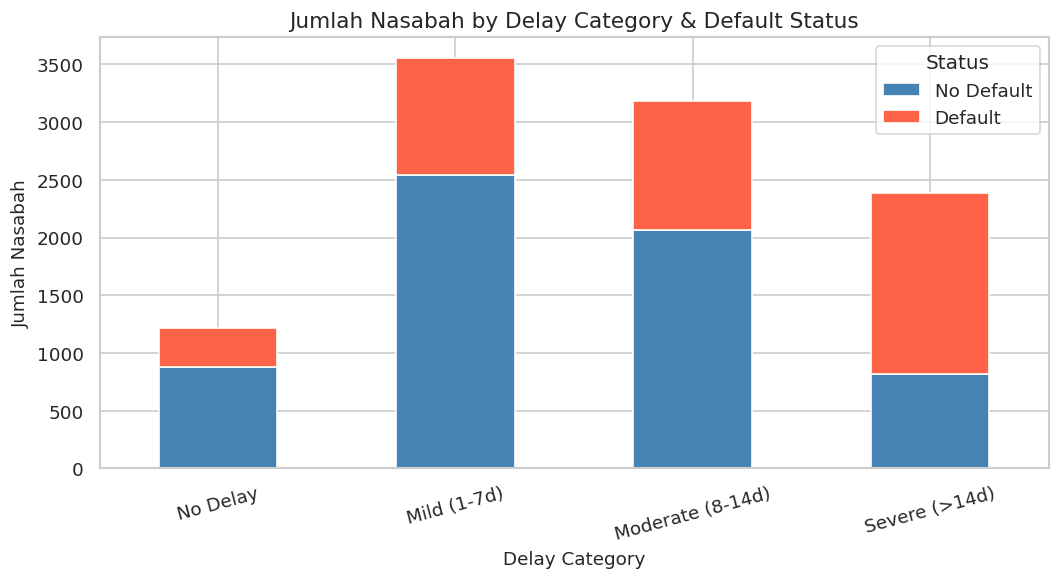

In [ ]:
delay_default = df_feat.groupby(['delay_category', 'default_flag'], observed=True) \
                        .size().unstack(fill_value=0)
delay_default.columns = ['No Default', 'Default']

fig, ax = plt.subplots(figsize=(9, 5))
delay_default.plot(kind='bar', stacked=True, ax=ax,
                   color=['steelblue', 'tomato'], edgecolor='white')
ax.set_title('Jumlah Nasabah by Delay Category & Default Status')
ax.set_ylabel('Jumlah Nasabah')
ax.set_xlabel('Delay Category')
ax.tick_params(axis='x', rotation=15)
ax.legend(title='Status')
plt.tight_layout()
plt.show()

### 4.11 Hexbin — DTI Ratio vs Missed Payments

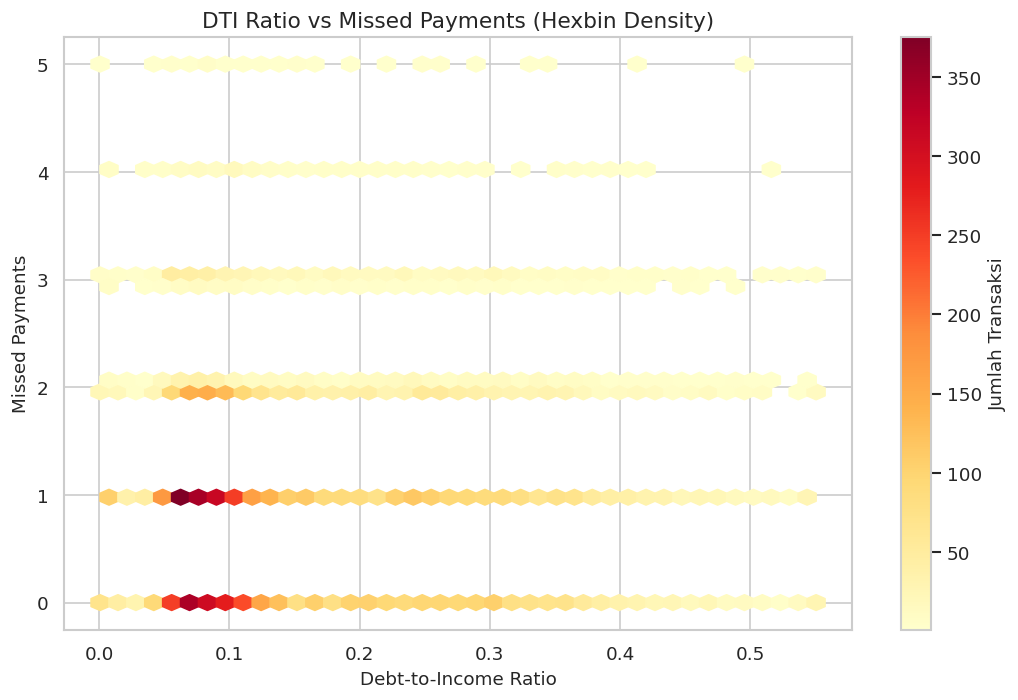

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
hb = ax.hexbin(df_feat['debt_to_income_ratio'], df_feat['missed_payments'],
               gridsize=40, cmap='YlOrRd', mincnt=1)
fig.colorbar(hb, ax=ax, label='Jumlah Transaksi')
ax.set_xlabel('Debt-to-Income Ratio')
ax.set_ylabel('Missed Payments')
ax.set_title('DTI Ratio vs Missed Payments (Hexbin Density)')
plt.tight_layout()
plt.show()

### 4.12 Perbandingan Mean — Default vs Non-Default

In [ ]:
num_eda = ['age', 'monthly_income', 'credit_score', 'purchase_amount',
           'repayment_delay_days', 'missed_payments', 'debt_to_income_ratio',
           'risk_score', 'app_usage_frequency']

df_feat.groupby('default_flag')[num_eda].mean().T.round(3)

default_flag,0,1
age,39.295,37.413
monthly_income,40968.951,25776.638
credit_score,483.607,392.881
purchase_amount,4097.027,3795.834
repayment_delay_days,7.205,11.142
missed_payments,0.799,1.353
debt_to_income_ratio,0.163,0.208
risk_score,176.968,232.230
app_usage_frequency,5.516,5.537


### 4.13 Chi-Square Test — Kategorikal vs Default

In [ ]:
results_chi = []
for col in ['employment_type', 'product_category', 'location', 'customer_segment']:
    ct = pd.crosstab(df_feat[col], df_feat['default_flag'])
    chi2, p, dof, _ = chi2_contingency(ct)
    results_chi.append({'feature': col, 'chi2': round(chi2, 2), 'p_value': round(p, 4), 'dof': dof})

pd.DataFrame(results_chi).sort_values('chi2', ascending=False)

,feature,chi2,p_value,dof
3,customer_segment,1313.45,0.0000,2
0,employment_type,418.81,0.0000,3
1,product_category,6.44,0.1683,4
2,location,2.13,0.8303,5


### 4.14 Point-Biserial Correlation — Numerik vs Default

In [ ]:
results_pb = []
for col in num_eda:
    corr, p = pointbiserialr(df_feat['default_flag'], df_feat[col])
    results_pb.append({'feature': col, 'r': round(corr, 4), 'p_value': round(p, 4)})

pd.DataFrame(results_pb).sort_values('r', key=abs, ascending=False)

,feature,r,p_value
7,risk_score,0.3995,0.0000
2,credit_score,-0.3242,0.0000
4,repayment_delay_days,0.2832,0.0000
1,monthly_income,-0.2743,0.0000
5,missed_payments,0.2723,0.0000
6,debt_to_income_ratio,0.1743,0.0000
3,purchase_amount,-0.0979,0.0000
0,age,-0.0757,0.0000
8,app_usage_frequency,0.0039,0.6944


---
## 5. Uji Hipotesis Statistik (Hypothesis Testing)
Bagian ini menguji beberapa hipotesis bisnis yang relevan untuk industri BNPL menggunakan uji statistik formal. Setiap hipotesis mengikuti 4 langkah standar: (1) definisi H0/H1, (2) cek asumsi data (normalitas & homogenitas varians), (3) uji statistik yang sesuai, (4) kesimpulan berdasarkan p-value (alpha = 0.05).

### 5.1 Hipotesis 1 — Status Pekerjaan vs Gagal Bayar
**Grup A:** `employment_type` = 'Salaried' | **Grup B:** `employment_type` = 'Unemployed' / 'Self-Employed'

**Pertanyaan:** Apakah persentase gagal bayar (`default_flag` = 1) berbeda secara signifikan antara karyawan bergaji tetap dan pelanggan yang tidak bekerja/wiraswasta?

- **H0:** Tidak ada hubungan antara status pekerjaan dan gagal bayar (proporsi default sama di kedua grup).
- **H1:** Ada hubungan antara status pekerjaan dan gagal bayar (proporsi default berbeda signifikan).
- **Uji:** Chi-Square Test of Independence (kategorikal vs kategorikal).

In [ ]:
h1_df = df_feat[df_feat['employment_type'].isin(['Salaried', 'Unemployed', 'Self-Employed'])].copy()
h1_df['emp_group'] = h1_df['employment_type'].apply(
    lambda x: 'Salaried' if x == 'Salaried' else 'Unemployed/Self-Employed'
)

ct_h1 = pd.crosstab(h1_df['emp_group'], h1_df['default_flag'])
display(ct_h1)

display(h1_df.groupby('emp_group', observed=True)['default_flag'].mean().mul(100).round(2).rename('default_rate_%'))

default_flag,0,1
emp_group,,
Salaried,1771,861
Unemployed/Self-Employed,3232,1950


,default_rate_%
emp_group,
Salaried,32.71
Unemployed/Self-Employed,37.63


In [ ]:
chi2_h1, p_h1, dof_h1, expected_h1 = chi2_contingency(ct_h1)

print(f"Chi-Square statistic : {chi2_h1:.4f}")
print(f"Degrees of freedom   : {dof_h1}")
print(f"P-value              : {p_h1:.6f}")
print(f"Expected freq (min)  : {expected_h1.min():.1f}  -> asumsi expected>=5 {'terpenuhi' if expected_h1.min() >= 5 else 'TIDAK terpenuhi'}")

alpha = 0.05
if p_h1 < alpha:
    print(f"\nKesimpulan: P-value ({p_h1:.6f}) < {alpha} -> Tolak H0.")
    print("Ada perbedaan signifikan proporsi gagal bayar antara Salaried vs Unemployed/Self-Employed.")
else:
    print(f"\nKesimpulan: P-value ({p_h1:.6f}) >= {alpha} -> Gagal tolak H0.")
    print("Tidak ada bukti perbedaan signifikan proporsi gagal bayar antara kedua grup.")

Chi-Square statistic : 18.1125
Degrees of freedom   : 1
P-value              : 0.000021
Expected freq (min)  : 946.8  -> asumsi expected>=5 terpenuhi

Kesimpulan: P-value (0.000021) < 0.05 -> Tolak H0.
Ada perbedaan signifikan proporsi gagal bayar antara Salaried vs Unemployed/Self-Employed.


#### Insight Hipotesis 1:
Berdasarkan hasil uji Chi-Square (p-value = 0.000021 < 0.05), kita menolak hipotesis nol (H0). Ini menunjukkan bahwa **ada perbedaan signifikan dalam proporsi gagal bayar antara pelanggan dengan status pekerjaan 'Salaried' dan 'Unemployed/Self-Employed'**. Proporsi gagal bayar untuk Salaried (32.7%) lebih rendah dibandingkan dengan gabungan Unemployed/Self-Employed.

### 5.2 Hipotesis 2 — Credit Score: Default vs Tidak Default
**Grup A:** `default_flag` = 0 (lancar) | **Grup B:** `default_flag` = 1 (gagal bayar)

**Pertanyaan:** Apakah pengguna yang gagal bayar memiliki rata-rata `credit_score` yang jauh lebih rendah dibandingkan pengguna yang lancar?

- **H0:** Rata-rata `credit_score` Grup A = Grup B (tidak ada perbedaan).
- **H1:** Rata-rata `credit_score` Grup A ≠ Grup B (ada perbedaan).
- **Uji:** Independent T-Test (jika distribusi normal) atau Mann-Whitney U Test (jika tidak normal), didahului cek Shapiro-Wilk & Levene.

In [ ]:
grp_A_h2 = df_feat.loc[df_feat['default_flag'] == 0, 'credit_score'].dropna()
grp_B_h2 = df_feat.loc[df_feat['default_flag'] == 1, 'credit_score'].dropna()

print(f"n Grup A (No Default) : {len(grp_A_h2)}, mean = {grp_A_h2.mean():.2f}, std = {grp_A_h2.std():.2f}")
print(f"n Grup B (Default)    : {len(grp_B_h2)}, mean = {grp_B_h2.mean():.2f}, std = {grp_B_h2.std():.2f}")

sample_A = grp_A_h2.sample(min(500, len(grp_A_h2)), random_state=42)
sample_B = grp_B_h2.sample(min(500, len(grp_B_h2)), random_state=42)

shapiro_A = stats.shapiro(sample_A)
shapiro_B = stats.shapiro(sample_B)
print(f"\nShapiro-Wilk Grup A: stat={shapiro_A.statistic:.4f}, p={shapiro_A.pvalue:.6f}")
print(f"Shapiro-Wilk Grup B: stat={shapiro_B.statistic:.4f}, p={shapiro_B.pvalue:.6f}")

levene_h2 = stats.levene(grp_A_h2, grp_B_h2)
print(f"\nLevene's Test       : stat={levene_h2.statistic:.4f}, p={levene_h2.pvalue:.6f}")

normal_h2 = (shapiro_A.pvalue > 0.05) and (shapiro_B.pvalue > 0.05)
print(f"\nAsumsi normal terpenuhi: {normal_h2}")

n Grup A (No Default) : 6305, mean = 483.61, std = 147.71
n Grup B (Default)    : 4040, mean = 392.88, std = 93.05

Shapiro-Wilk Grup A: stat=0.9370, p=0.000000
Shapiro-Wilk Grup B: stat=0.8544, p=0.000000

Levene's Test       : stat=1558.6492, p=0.000000

Asumsi normal terpenuhi: False


In [ ]:
alpha = 0.05

if normal_h2:
    equal_var_h2 = levene_h2.pvalue > alpha
    test_stat_h2, p_h2 = stats.ttest_ind(grp_A_h2, grp_B_h2, equal_var=equal_var_h2)
    test_name_h2 = f"Independent T-Test ({'equal_var' if equal_var_h2 else 'Welch, unequal_var'})"
else:
    test_stat_h2, p_h2 = stats.mannwhitneyu(grp_A_h2, grp_B_h2, alternative='two-sided')
    test_name_h2 = "Mann-Whitney U Test"

print(f"Uji yang digunakan : {test_name_h2}")
print(f"Statistic          : {test_stat_h2:.4f}")
print(f"P-value            : {p_h2:.6f}")

if p_h2 < alpha:
    print(f"\nKesimpulan: P-value ({p_h2:.6f}) < {alpha} -> Tolak H0.")
    print(f"Rata-rata credit_score berbeda signifikan antara Default vs Tidak Default "
          f"(No Default mean={grp_A_h2.mean():.1f} vs Default mean={grp_B_h2.mean():.1f}).")
else:
    print(f"\nKesimpulan: P-value ({p_h2:.6f}) >= {alpha} -> Gagal tolak H0.")
    print("Tidak ada bukti perbedaan signifikan rata-rata credit_score antara kedua grup.")

Uji yang digunakan : Mann-Whitney U Test
Statistic          : 17296784.5000
P-value            : 0.000000

Kesimpulan: P-value (0.000000) < 0.05 -> Tolak H0.
Rata-rata credit_score berbeda signifikan antara Default vs Tidak Default (No Default mean=483.6 vs Default mean=392.9).


#### Insight Hipotesis 2:
Hasil uji Mann-Whitney U (p-value = 0.000000 < 0.05) sangat signifikan, sehingga kita menolak hipotesis nol (H0). Ini membuktikan bahwa **rata-rata credit score berbeda secara signifikan antara pelanggan yang tidak gagal bayar dan yang gagal bayar**. Pelanggan yang tidak gagal bayar memiliki rata-rata credit score yang jauh lebih tinggi (483.6) dibandingkan dengan pelanggan yang gagal bayar (392.9).

### 5.3 Hipotesis 3 — Tenor Cicilan vs Keterlambatan Pembayaran
**Grup A:** `bnpl_installments` ≤ 6 bulan (tenor pendek) | **Grup B:** `bnpl_installments` > 6 bulan (tenor panjang)

**Pertanyaan:** Apakah pelanggan dengan tenor panjang memiliki rata-rata `repayment_delay_days` yang lebih tinggi dibandingkan tenor pendek?

- **H0:** Rata-rata `repayment_delay_days` Grup A = Grup B.
- **H1:** Rata-rata `repayment_delay_days` Grup A ≠ Grup B.
- **Uji:** Independent T-Test atau Mann-Whitney U Test, didahului cek Shapiro-Wilk & Levene.

In [ ]:
grp_A_h3 = df_feat.loc[df_feat['bnpl_installments'] <= 6, 'repayment_delay_days'].dropna()
grp_B_h3 = df_feat.loc[df_feat['bnpl_installments'] > 6, 'repayment_delay_days'].dropna()

print(f"n Grup A (Tenor <=6bln) : {len(grp_A_h3)}, mean = {grp_A_h3.mean():.2f}, std = {grp_A_h3.std():.2f}")
print(f"n Grup B (Tenor >6bln)  : {len(grp_B_h3)}, mean = {grp_B_h3.mean():.2f}, std = {grp_B_h3.std():.2f}")

np.random.seed(42)
sample_A3 = grp_A_h3.sample(min(500, len(grp_A_h3)), random_state=42)
sample_B3 = grp_B_h3.sample(min(500, len(grp_B_h3)), random_state=42)

shapiro_A3 = stats.shapiro(sample_A3)
shapiro_B3 = stats.shapiro(sample_B3)
print(f"\nShapiro-Wilk Grup A: stat={shapiro_A3.statistic:.4f}, p={shapiro_A3.pvalue:.6f}")
print(f"Shapiro-Wilk Grup B: stat={shapiro_B3.statistic:.4f}, p={shapiro_B3.pvalue:.6f}")

levene_h3 = stats.levene(grp_A_h3, grp_B_h3)
print(f"\nLevene's Test       : stat={levene_h3.statistic:.4f}, p={levene_h3.pvalue:.6f}")

normal_h3 = (shapiro_A3.pvalue > 0.05) and (shapiro_B3.pvalue > 0.05)
print(f"\nAsumsi normal terpenuhi: {normal_h3}")

n Grup A (Tenor <=6bln) : 5162, mean = 8.65, std = 6.76
n Grup B (Tenor >6bln)  : 5183, mean = 8.83, std = 6.80

Shapiro-Wilk Grup A: stat=0.9351, p=0.000000
Shapiro-Wilk Grup B: stat=0.9417, p=0.000000

Levene's Test       : stat=0.6737, p=0.411792

Asumsi normal terpenuhi: False


In [ ]:
alpha = 0.05

if normal_h3:
    equal_var_h3 = levene_h3.pvalue > alpha
    test_stat_h3, p_h3 = stats.ttest_ind(grp_A_h3, grp_B_h3, equal_var=equal_var_h3)
    test_name_h3 = f"Independent T-Test ({'equal_var' if equal_var_h3 else 'Welch, unequal_var'})"
else:
    test_stat_h3, p_h3 = stats.mannwhitneyu(grp_A_h3, grp_B_h3, alternative='two-sided')
    test_name_h3 = "Mann-Whitney U Test"

print(f"Uji yang digunakan : {test_name_h3}")
print(f"Statistic          : {test_stat_h3:.4f}")
print(f"P-value            : {p_h3:.6f}")

if p_h3 < alpha:
    print(f"\nKesimpulan: P-value ({p_h3:.6f}) < {alpha} -> Tolak H0.")
    print(f"Rata-rata repayment_delay_days berbeda signifikan antara tenor pendek (mean={grp_A_h3.mean():.1f}) "
          f"vs tenor panjang (mean={grp_B_h3.mean():.1f}).")
else:
    print(f"\nKesimpulan: P-value ({p_h3:.6f}) >= {alpha} -> Gagal tolak H0.")
    print("Tidak ada bukti perbedaan signifikan rata-rata keterlambatan antara tenor pendek vs panjang.")

Uji yang digunakan : Mann-Whitney U Test
Statistic          : 13144072.5000
P-value            : 0.123891

Kesimpulan: P-value (0.123891) >= 0.05 -> Gagal tolak H0.
Tidak ada bukti perbedaan signifikan rata-rata keterlambatan antara tenor pendek vs panjang.


#### Insight Hipotesis 3:
Dengan p-value = 0.123891 (lebih besar dari 0.05), kita gagal menolak hipotesis nol (H0). Ini berarti **tidak ada bukti perbedaan signifikan dalam rata-rata hari keterlambatan pembayaran antara pelanggan dengan tenor cicilan pendek (≤ 6 bulan) dan tenor panjang (> 6 bulan)**. Artinya, tenor cicilan tidak secara signifikan mempengaruhi berapa lama pelanggan menunda pembayaran.

### 5.4 Hipotesis 4 — Perilaku Belanja per Customer Segment
**Grup:** `customer_segment` (High Risk, Medium Risk, Low Risk)

**Pertanyaan:** Apakah `purchase_amount` berbeda secara signifikan di antara ketiga segmen risiko?

- **H0:** Rata-rata `purchase_amount` sama di seluruh segmen (High/Medium/Low Risk).
- **H1:** Minimal ada satu segmen dengan rata-rata `purchase_amount` yang berbeda.
- **Uji:** ANOVA (jika asumsi normalitas & homogenitas varians terpenuhi) atau Kruskal-Wallis (jika tidak), didahului cek Shapiro-Wilk & Levene.

In [ ]:
segments_h4 = df_feat['customer_segment'].cat.categories.tolist()
groups_h4 = [df_feat.loc[df_feat['customer_segment'] == seg, 'purchase_amount'].dropna() for seg in segments_h4]

for seg, g in zip(segments_h4, groups_h4):
    print(f"{seg}: n={len(g)}, mean={g.mean():.2f}, std={g.std():.2f}")

np.random.seed(42)
shapiro_results_h4 = []
for seg, g in zip(segments_h4, groups_h4):
    s = g.sample(min(500, len(g)), random_state=42)
    sh = stats.shapiro(s)
    shapiro_results_h4.append((seg, sh.statistic, sh.pvalue))
    print(f"\nShapiro-Wilk {seg}: stat={sh.statistic:.4f}, p={sh.pvalue:.6f}")

levene_h4 = stats.levene(*groups_h4)
print(f"\nLevene's Test (3 grup): stat={levene_h4.statistic:.4f}, p={levene_h4.pvalue:.6f}")

normal_h4 = all(p > 0.05 for _, _, p in shapiro_results_h4)
equal_var_h4 = levene_h4.pvalue > 0.05
print(f"\nAsumsi normal terpenuhi     : {normal_h4}")
print(f"Asumsi homogen varians terpenuhi: {equal_var_h4}")

High Risk: n=7569, mean=3758.29, std=1549.66
Low Risk: n=576, mean=4774.60, std=967.58
Medium Risk: n=2200, mean=4531.92, std=1202.79

Shapiro-Wilk High Risk: stat=0.7911, p=0.000000

Shapiro-Wilk Low Risk: stat=0.2288, p=0.000000

Shapiro-Wilk Medium Risk: stat=0.4172, p=0.000000

Levene's Test (3 grup): stat=384.8869, p=0.000000

Asumsi normal terpenuhi     : False
Asumsi homogen varians terpenuhi: False


In [ ]:
alpha = 0.05

if normal_h4 and equal_var_h4:
    stat_h4, p_h4 = stats.f_oneway(*groups_h4)
    test_name_h4 = "ANOVA (Analysis of Variance)"
else:
    stat_h4, p_h4 = stats.kruskal(*groups_h4)
    test_name_h4 = "Kruskal-Wallis H Test"

print(f"Uji yang digunakan : {test_name_h4}")
print(f"Statistic          : {stat_h4:.4f}")
print(f"P-value            : {p_h4:.6f}")

if p_h4 < alpha:
    print(f"\nKesimpulan: P-value ({p_h4:.6f}) < {alpha} -> Tolak H0.")
    print("Rata-rata purchase_amount berbeda signifikan di antara segmen High/Medium/Low Risk.")
    print("(Uji lanjutan post-hoc, mis. Tukey HSD atau Dunn's test, bisa dilakukan untuk mengetahui pasangan segmen mana yang berbeda.)")
else:
    print(f"\nKesimpulan: P-value ({p_h4:.6f}) >= {alpha} -> Gagal tolak H0.")
    print("Tidak ada bukti perbedaan signifikan purchase_amount antar segmen risiko.")

Uji yang digunakan : Kruskal-Wallis H Test
Statistic          : 990.0139
P-value            : 0.000000

Kesimpulan: P-value (0.000000) < 0.05 -> Tolak H0.
Rata-rata purchase_amount berbeda signifikan di antara segmen High/Medium/Low Risk.
(Uji lanjutan post-hoc, mis. Tukey HSD atau Dunn's test, bisa dilakukan untuk mengetahui pasangan segmen mana yang berbeda.)


#### Insight Hipotesis 4:
Hasil uji Kruskal-Wallis (p-value = 0.000000 < 0.05) menunjukkan bahwa kita menolak hipotesis nol (H0). Ini mengindikasikan bahwa **rata-rata purchase amount berbeda secara signifikan di antara segmen risiko pelanggan (High Risk, Medium Risk, Low Risk)**. Pelanggan Low Risk memiliki rata-rata purchase amount tertinggi, sementara High Risk memiliki yang terendah. Diperlukan uji post-hoc untuk mengetahui pasangan segmen mana yang memiliki perbedaan signifikan.

In [ ]:
print('--- Contoh Sederhana Uji Hipotesis (Mann-Whitney U Test) ---')

grp_A_h2 = df_feat.loc[df_feat['default_flag'] == 0, 'credit_score'].dropna()
grp_B_h2 = df_feat.loc[df_feat['default_flag'] == 1, 'credit_score'].dropna()

stat_h2_simple, p_h2_simple = stats.mannwhitneyu(grp_A_h2, grp_B_h2, alternative='two-sided')

print(f"\nStatistik Uji (Mann-Whitney U): {stat_h2_simple:.4f}")
print(f"P-value                    : {p_h2_simple:.6f}")

alpha = 0.05
if p_h2_simple < alpha:
    print(f"Kesimpulan: P-value ({p_h2_simple:.6f}) < {alpha} -> Tolak H0.")
    print("Ada perbedaan signifikan pada credit_score antara kedua grup.")
else:
    print(f"Kesimpulan: P-value ({p_h2_simple:.6f}) >= {alpha} -> Gagal tolak H0.")
    print("Tidak ada perbedaan signifikan pada credit_score antara kedua grup.")

--- Contoh Sederhana Uji Hipotesis (Mann-Whitney U Test) ---

Statistik Uji (Mann-Whitney U): 17296784.5000
P-value                    : 0.000000
Kesimpulan: P-value (0.000000) < 0.05 -> Tolak H0.
Ada perbedaan signifikan pada credit_score antara kedua grup.


### 5.5 Ringkasan Hasil Uji Hipotesis
| # | Hipotesis | Uji | H0 |
|---|-----------|-----|----|
| 1 | Status pekerjaan vs gagal bayar | Chi-Square Test of Independence | Tidak ada hubungan antara employment_type dan default_flag |
| 2 | Credit score: default vs tidak | T-Test / Mann-Whitney U | Rata-rata credit_score sama antara default vs tidak default |
| 3 | Tenor cicilan vs keterlambatan | T-Test / Mann-Whitney U | Rata-rata repayment_delay_days sama antara tenor pendek vs panjang |
| 4 | Belanja per customer segment | ANOVA / Kruskal-Wallis | Rata-rata purchase_amount sama di seluruh segmen risiko |

Kesimpulan p-value aktual untuk masing-masing hipotesis tercetak pada output cell di atas (lihat blok "Kesimpulan" setelah setiap uji). Jika p-value < 0.05, H0 ditolak dan perbedaan antar kelompok dianggap signifikan secara statistik.

---
## 6. Customer Segmentation Analysis
Pola risiko kredit sudah teruji secara statistik pada bagian sebelumnya. Langkah berikutnya adalah menerjemahkan data menjadi segmen bisnis yang actionable untuk tim marketing. Bagian ini menjawab kebutuhan **Customer Segmentation**: mengelompokkan pelanggan berdasarkan **demografi** (usia, status pekerjaan), **perilaku pembelian** (nilai pembelian & frekuensi aktivitas), dan **lokasi geografis**, untuk mendukung strategi pemasaran.

> ⚠️ **Catatan penting**: kolom `customer_segment` pada dataset ini ternyata berisi label **`High Risk` / `Medium Risk` / `Low Risk`** — yaitu segmentasi berbasis **risiko kredit**, bukan segmentasi demografi/perilaku/geografis untuk marketing. Kolom tersebut sudah dipakai pada bagian credit risk (4.9, 4.13, dst). Untuk kebutuhan **customer segmentation** pada bagian ini, kita membangun segmen baru (`customer_value_segment`) dari atribut nilai pembelian dan keterlibatan pelanggan (engagement), sehingga benar-benar merepresentasikan kebutuhan pemasaran, bukan risiko.

### 6.1 Membangun Customer Value Segment (Perilaku Pembelian)

In [ ]:
df_feat['purchase_tier'] = pd.cut(
    df_feat['purchase_amount'],
    bins=[0, 2500, 4999.99, df_feat['purchase_amount'].max()],
    labels=['Low Value', 'Mid Value', 'High Value'],
    include_lowest=True
)

df_feat['engagement_tier'] = pd.cut(
    df_feat['app_usage_frequency'],
    bins=[0, df_feat['app_usage_frequency'].median(), df_feat['app_usage_frequency'].max()],
    labels=['Low Engagement', 'High Engagement']
)

df_feat['customer_value_segment'] = (
    df_feat['purchase_tier'].astype(str) + ' / ' + df_feat['engagement_tier'].astype(str)
)

df_feat['customer_value_segment'].value_counts()

,count
customer_value_segment,
High Value / Low Engagement,3051
High Value / High Engagement,3002
Mid Value / High Engagement,1098
Mid Value / Low Engagement,1091
Low Value / High Engagement,1068
Low Value / Low Engagement,1035


### 6.2 Profil Setiap Customer Value Segment
Ukuran segmen, demografi, dan nilai ekonomi tiap segmen — basis untuk menentukan segmen mana yang paling besar populasinya dan paling bernilai (high-value) untuk ditarget kampanye marketing.

In [ ]:
segment_profile = df_feat.groupby('customer_value_segment', observed=True).agg(
    jumlah_user=('customer_value_segment', 'count'),
    avg_age=('age', 'mean'),
    avg_income=('monthly_income', 'mean'),
    avg_purchase=('purchase_amount', 'mean'),
    avg_installments=('bnpl_installments', 'mean'),
    avg_app_usage=('app_usage_frequency', 'mean'),
).round(2)

segment_profile['pct_user'] = (segment_profile['jumlah_user'] / segment_profile['jumlah_user'].sum() * 100).round(2)
segment_profile.sort_values('jumlah_user', ascending=False)

,jumlah_user,avg_age,avg_income,avg_purchase,avg_installments,avg_app_usage,pct_user
customer_value_segment,,,,,,,
High Value / Low Engagement,3051,39.68,49003.94,5000.00,7.55,3.28,29.49
High Value / High Engagement,3002,39.97,48650.00,5000.00,7.48,7.77,29.02
Mid Value / High Engagement,1098,37.30,16349.42,3661.42,7.48,7.75,10.61
Mid Value / Low Engagement,1091,37.98,16139.59,3697.11,7.39,3.29,10.55
Low Value / High Engagement,1068,35.83,14979.81,1333.16,7.41,7.81,10.32
Low Value / Low Engagement,1035,35.93,14811.72,1376.16,7.41,3.26,10.00


### 6.3 Visualisasi Customer Value Segment

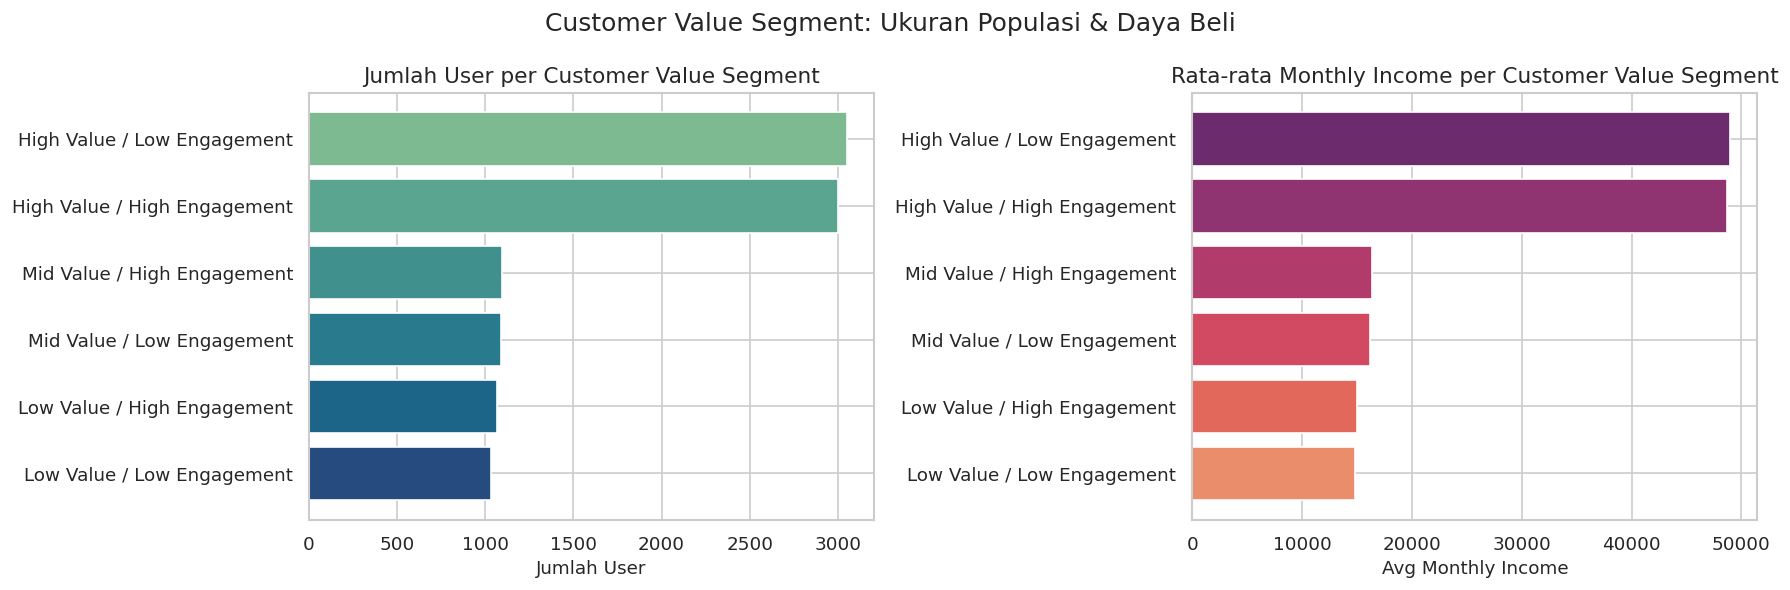

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

vc_seg = df_feat['customer_value_segment'].value_counts()
axes[0].barh(vc_seg.index, vc_seg.values, color=sns.color_palette('crest', len(vc_seg)))
axes[0].set_title('Jumlah User per Customer Value Segment')
axes[0].set_xlabel('Jumlah User')
axes[0].invert_yaxis()

avg_income_seg = df_feat.groupby('customer_value_segment', observed=True)['monthly_income'].mean().sort_values()
axes[1].barh(avg_income_seg.index, avg_income_seg.values, color=sns.color_palette('flare', len(avg_income_seg)))
axes[1].set_title('Rata-rata Monthly Income per Customer Value Segment')
axes[1].set_xlabel('Avg Monthly Income')

plt.suptitle('Customer Value Segment: Ukuran Populasi & Daya Beli', fontsize=15)
plt.tight_layout()
plt.show()

### 6.4 Segmentasi Geografis (Berdasarkan Lokasi)
Melihat distribusi user dan rata-rata nilai pembelian per lokasi — untuk menentukan wilayah mana yang potensial untuk ekspansi pemasaran.

In [ ]:
geo_profile = df_feat.groupby('location', observed=True).agg(
    jumlah_user=('location', 'count'),
    avg_purchase=('purchase_amount', 'mean'),
    avg_income=('monthly_income', 'mean'),
    avg_app_usage=('app_usage_frequency', 'mean'),
).round(2).sort_values('jumlah_user', ascending=False)

geo_profile

,jumlah_user,avg_purchase,avg_income,avg_app_usage
location,,,,
Germany,1760,3989.06,34691.97,5.62
Canada,1740,3964.91,34081.90,5.46
USA,1736,3960.06,35036.87,5.58
India,1723,4004.58,35073.89,5.45
Australia,1722,3982.16,35730.79,5.56
UK,1664,3975.59,35638.06,5.47


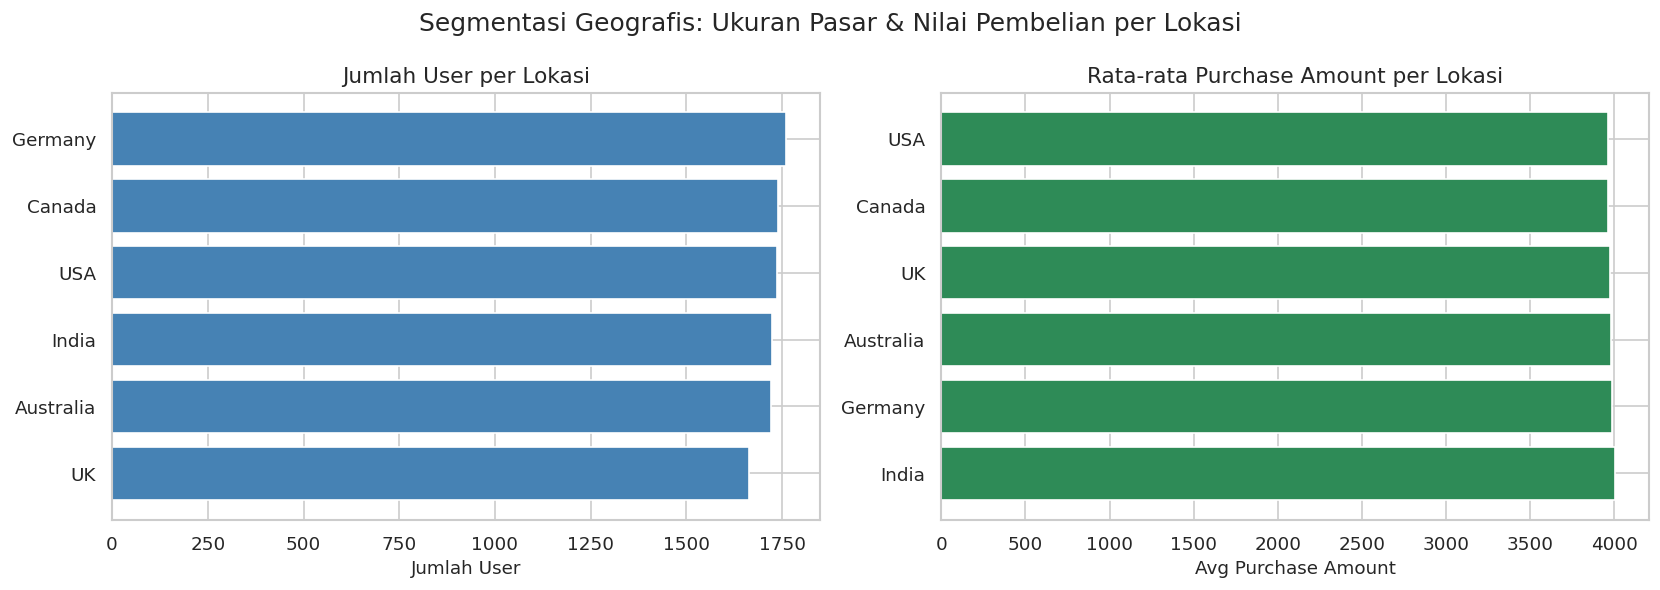

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

geo_sorted = geo_profile.sort_values('jumlah_user', ascending=False)
axes[0].barh(geo_sorted.index, geo_sorted['jumlah_user'], color='steelblue')
axes[0].set_title('Jumlah User per Lokasi')
axes[0].set_xlabel('Jumlah User')
axes[0].invert_yaxis()

geo_sorted2 = geo_profile.sort_values('avg_purchase', ascending=False)
axes[1].barh(geo_sorted2.index, geo_sorted2['avg_purchase'], color='seagreen')
axes[1].set_title('Rata-rata Purchase Amount per Lokasi')
axes[1].set_xlabel('Avg Purchase Amount')

plt.suptitle('Segmentasi Geografis: Ukuran Pasar & Nilai Pembelian per Lokasi', fontsize=15)
plt.tight_layout()
plt.show()

### 6.5 Segmentasi Demografis (Usia & Status Pekerjaan)
Fokus pada **perilaku pembelian** — melihat kelompok usia & pekerjaan mana yang paling besar nilai belanjanya, untuk personalisasi penawaran.

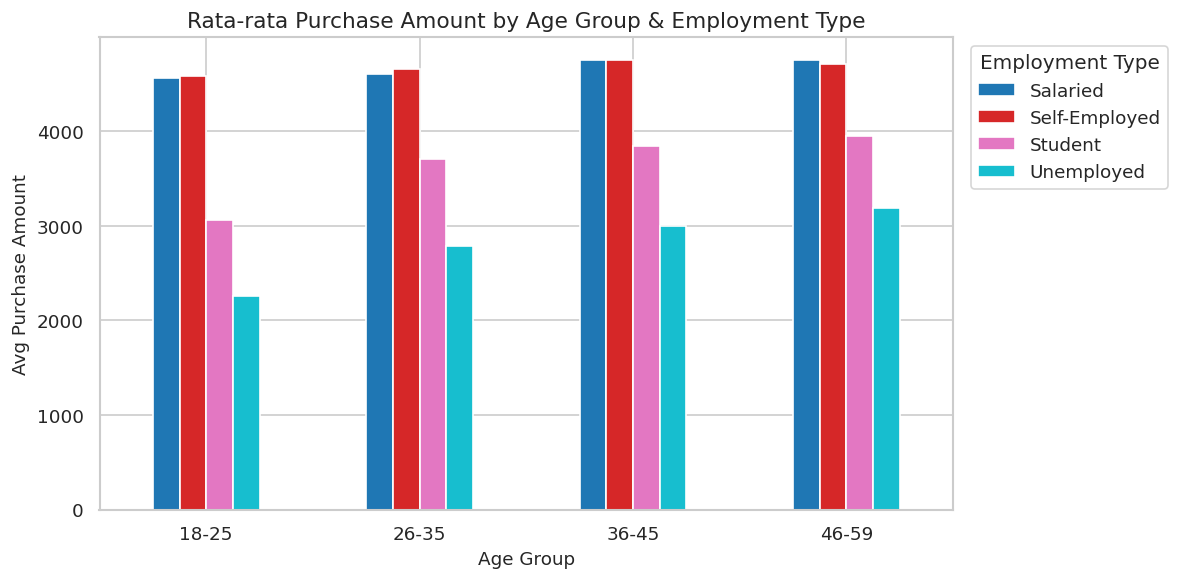

In [ ]:
demo_pivot_purchase = df_feat.groupby(['age_group', 'employment_type'], observed=True)['purchase_amount'] \
                              .mean().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
demo_pivot_purchase.plot(kind='bar', ax=ax, colormap='tab10', edgecolor='white')
ax.set_title('Rata-rata Purchase Amount by Age Group & Employment Type')
ax.set_ylabel('Avg Purchase Amount')
ax.set_xlabel('Age Group')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Employment Type', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### 6.6 Preferensi Kategori Produk per Customer Value Segment
Mengetahui kategori produk favorit tiap segmen nilai pelanggan untuk menyesuaikan strategi promosi/penawaran per segmen.

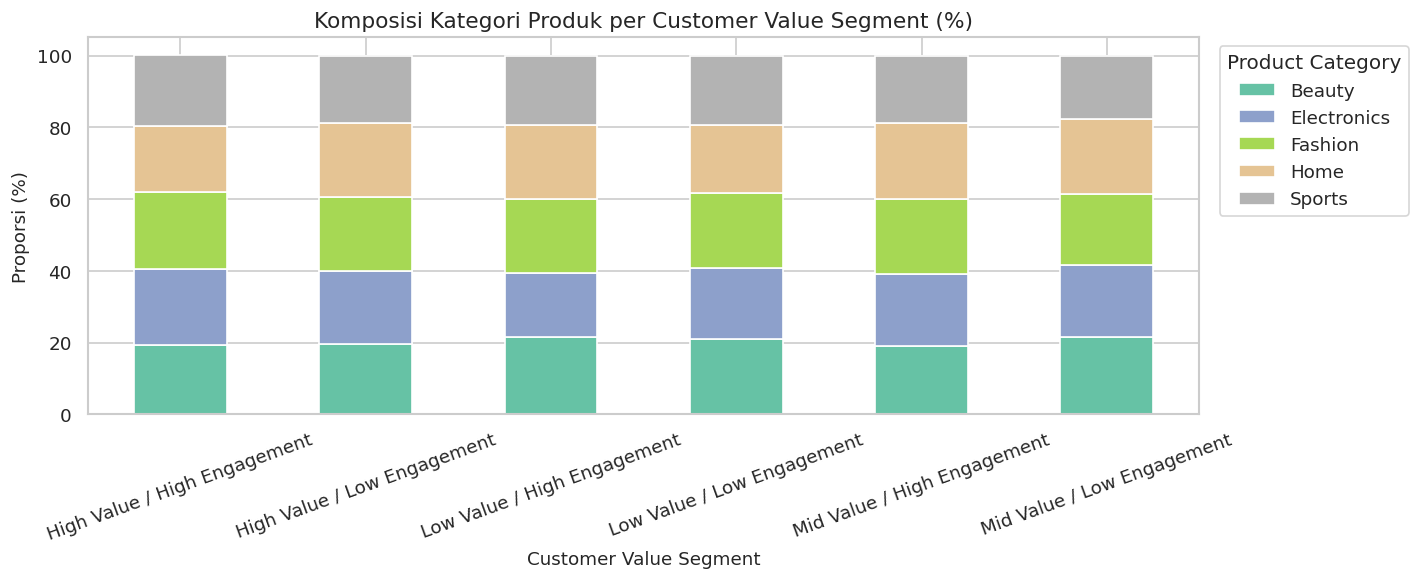

In [ ]:
pref_pivot = pd.crosstab(
    df_feat['customer_value_segment'], df_feat['product_category'], normalize='index'
).mul(100).round(1)

fig, ax = plt.subplots(figsize=(12, 5))
pref_pivot.plot(kind='bar', stacked=True, ax=ax, colormap='Set2', edgecolor='white')
ax.set_title('Komposisi Kategori Produk per Customer Value Segment (%)')
ax.set_ylabel('Proporsi (%)')
ax.set_xlabel('Customer Value Segment')
ax.tick_params(axis='x', rotation=20)
ax.legend(title='Product Category', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### 6.7 Ringkasan Insight Customer Segmentation
- **`customer_segment` bawaan dataset** (High/Medium/Low Risk) adalah segmentasi **risiko kredit**, bukan segmentasi marketing — sudah konsisten dipakai di analisis credit risk (bagian 4.1–4.14).
- **`customer_value_segment` (baru)** dibangun dari kombinasi nilai pembelian (Low/Mid/High Value) dan engagement (Low/High) — ini segmentasi perilaku pembelian yang relevan untuk marketing (4.15.1–4.15.3).
- **Segmentasi geografis** (4.15.4) menunjukkan lokasi dengan basis pelanggan terbesar dan rata-rata pembelian tertinggi, berguna untuk prioritas ekspansi/promosi regional.
- **Segmentasi demografis** (4.15.5) menunjukkan kombinasi age group × employment type dengan nilai belanja tertinggi, berguna untuk personalisasi penawaran.
- **Preferensi produk per value segment** (4.15.6) membantu menentukan kategori produk yang perlu dipromosikan ke masing-masing segmen.

Dengan struktur ini, notebook menjawab dua kebutuhan analisis yang berbeda secara eksplisit: **credit risk management** (bagian 4.1–4.14, berbasis `customer_segment`/risk) dan **customer segmentation untuk strategi pemasaran** (bagian 4.15, berbasis demografi, lokasi, dan `customer_value_segment`).

---
## 7. Export Dataset Bersih
Semua tahapan cerita analisis — pemahaman data, pembersihan, rekayasa fitur, eksplorasi, uji hipotesis, hingga segmentasi bisnis — dirangkum menjadi satu dataset final yang siap dipakai untuk pelaporan maupun pemodelan lanjutan.


In [ ]:
df_feat.to_csv('../data/bnpl_clean_featured.csv', index=False)
df_feat.to_parquet('../data/bnpl_clean_featured.parquet', index=False)

display(df_feat.shape)
display(df_feat.dtypes)
df_feat.isnull().sum()

(10345, 32)

,0
user_id,int64
age,int64
employment_type,category
monthly_income,float64
credit_score,int64
purchase_amount,float64
product_category,category
bnpl_installments,int64
repayment_delay_days,int64
missed_payments,int64


,0
user_id,0
age,0
employment_type,0
monthly_income,0
credit_score,0
purchase_amount,0
product_category,0
bnpl_installments,0
repayment_delay_days,0
missed_payments,0


---
## 8. Kesimpulan & Rekomendasi Bisnis
Bagian ini merangkum seluruh alur analisis (pemahaman data → pembersihan → rekayasa fitur → EDA → uji hipotesis → segmentasi) menjadi temuan utama dan rekomendasi yang dapat ditindaklanjuti oleh tim bisnis.

### 8.1 Temuan Utama
| # | Temuan | Bukti |
|---|--------|-------|
| 1 | **Tingkat gagal bayar tinggi**: 39,05% dari 10.345 pelanggan | Distribusi `default_flag` (bagian 1.10) |
| 2 | **Status pekerjaan menentukan risiko**: pelanggan *Unemployed* dan *Student* gagal bayar sekitar 48–49%, jauh di atas *Self-Employed* (sekitar 26%) | Chi-Square `employment_type` χ² = 418,81, p < 0,0001; H1 ditolak (bagian 4.13 dan 5.1) |
| 3 | **Kapasitas finansial lebih menentukan daripada perilaku digital**: rata-rata credit score pelanggan gagal bayar jauh lebih rendah (392,9 vs 483,6) | Mann-Whitney U, p < 0,000001; H2 ditolak (bagian 5.2) |
| 4 | **Lokasi dan kategori produk tidak berpengaruh signifikan** terhadap gagal bayar | Chi-Square `location` p = 0,830 dan `product_category` p = 0,168 (bagian 4.13) |
| 5 | **Frekuensi penggunaan aplikasi tidak memprediksi gagal bayar** | Point-Biserial `app_usage_frequency` r = 0,0039 (bagian 4.14) |
| 6 | **Tenor cicilan saja tidak memprediksi keterlambatan**: rata-rata keterlambatan tenor pendek 8,65 hari vs tenor panjang 8,83 hari | Mann-Whitney U, p = 0,1239; H3 gagal ditolak (bagian 5.3) |
| 7 | **Pelanggan berisiko rendah justru berbelanja paling besar**: rata-rata belanja Low Risk 4.775 vs High Risk 3.758 | Kruskal-Wallis H = 990,01, p < 0,000001; H4 ditolak (bagian 5.4) |
| 8 | **Keterlambatan 1–7 hari adalah kelompok terbesar** (3.557 pelanggan), sehingga menjadi jendela intervensi dini terbaik | Distribusi `delay_category` (bagian 3.3) |
| 9 | **Distribusi segmen risiko**: High Risk 73,17% (7.569), Medium Risk 21,27% (2.200), Low Risk 5,57% (576) | Distribusi `customer_segment` (bagian 1.11) |

### 8.2 Rekomendasi Bisnis
| # | Rekomendasi | Pemilik | Tindakan |
|---|-------------|---------|----------|
| 1 | **Limit kredit dinamis berdasarkan segmen risiko** | Credit & Risk Management | *High Risk* (73,17% pelanggan): batasi limit hingga 50% dari limit standar dan wajibkan verifikasi pendapatan yang ketat. *Medium Risk* (21,27%): limit standar dengan pemantauan pembayaran berkala. *Low Risk* (5,57%): layak mendapat kenaikan limit dan program loyalitas. |
| 2 | **Sistem peringatan dini berbasis hari keterlambatan** | Collections & Customer Success | Pengingat otomatis pada hari ke-3 (sebelum rata-rata keterlambatan 8,74 hari), pemberitahuan dampak terhadap credit score pada hari ke-7, dan peringatan keras pada hari ke-14. Masukkan pelanggan yang terlambat lebih dari 7 hari ke daftar pantauan otomatis. |
| 3 | **Perkuat proses onboarding untuk segmen *Student* dan *Unemployed*** | Onboarding & Underwriting | Wajibkan bukti sumber pendapatan alternatif (mutasi rekening, uang saku, transfer keluarga) dan syarat penjamin (*guarantor*) bila pendapatan tidak memenuhi ambang minimum. Pelonggaran berbasis usia hanya diterapkan pada segmen *Salaried* dan *Self-Employed*. |
| 4 | **Re-engagement dan alokasi promosi yang lebih tepat** | Product & Marketing | Alihkan anggaran promosi segmen *High Risk* ke kampanye literasi keuangan dan pengingat pembayaran. Arahkan insentif *cashback* ke pelanggan *Low/Medium Risk* yang rata-rata belanjanya (4.775 / 4.532) jauh di atas *High Risk* (3.758). Karena komposisi kategori produk relatif merata antarsegmen, strategi *cross-category bundling* lebih efisien daripada penargetan per kategori. |

### 8.3 Keterbatasan & Langkah Lanjutan
- **Analisis bersifat asosiatif**: hubungan yang teruji secara statistik tidak otomatis menunjukkan hubungan sebab-akibat.
- **Multikolinearitas**: `monthly_income` dan `credit_score` berkorelasi sangat kuat (sekitar 0,96). Pada pemodelan prediktif, pertahankan salah satunya agar tidak terjadi pembobotan ganda.
- **Fitur `total_debt_estimate`**: statistik deskriptifnya (kuartil dan nilai maksimum 5.000) hampir identik dengan `purchase_amount`. Fitur ini sebaiknya tidak ditafsirkan sebagai eksposur utang yang independen, dan estimasi nilai eksposur gagal bayar perlu divalidasi dengan data *write-off*/pemulihan aktual.
- **Proporsi High Risk yang sangat besar (73,17%)** menunjukkan bahwa ambang segmentasi bawaan dataset perlu dikalibrasi ulang sebelum dipakai untuk menetapkan kebijakan limit.
- **Langkah lanjutan**: membangun model prediktif skor risiko per pelanggan (misalnya Logistic Regression atau Gradient Boosting) dengan evaluasi AUC dan Precision-Recall, sehingga analisis berkembang dari *insight* menjadi alat pendukung keputusan.